# Descargamos el dataset

In [1]:
from os import path
from wget import download
import pandas as pd
import matplotlib.pyplot as plt

RUTA_CSV = "data/global_food_nutrition.csv"
URL = "https://drive.google.com/uc?export=download&id=1IyK0jgDmyde9jdAT6hJFtjSWIYT3yaVz"

if not path.exists(RUTA_CSV):
    download(URL, out=RUTA_CSV)
else:
    print("El archivo ya existe")

ModuleNotFoundError: No module named 'wget'

# Analisis parte 1

## Leemos el archivo y analizamos los primeros detalles

In [ ]:
# Abrimos los primeros 5 elementos del archivo para ver que campos tiene y algunos de sus valores
food_data_set = pd.read_csv(RUTA_CSV)

food_data_set.head()

,product_name,brands,categories,ingredients,nutriscore_grade,nova_group,ecoscore_grade,allergens,energy_kcal,fat_100g,...,proteins_100g,salt_100g,sodium_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,food_type
0,Sidi Ali,سيدي علي,"en:beverages-and-beverages-preparations, en:be...",OBD1 999 999 1112606 266963207 mb,A,NaN,NOT-APPLICABLE,NaN,0.0,0.0,...,0.0,0.000000,0.000000,False,False,False,False,False,False,Branded/Packaged
1,Perly,Perly,"en:dairies, en:fermented-foods, en:fermented-m...","milk cream, cream, sugar, banana, bacteria",UNKNOWN,3.0,B,"en:banana, en:milk",97.0,3.0,...,8.0,NaN,NaN,False,True,False,False,False,False,Branded/Packaged
2,Sidi Ali,Sidi Ali,"en:beverages-and-beverages-preparations, en:be...","Sodium, Calcium, Magnésium, Potassium, Bicarbo...",A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,...,NaN,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
3,Eau minérale naturelle,sidi ali,"en:beverages-and-beverages-preparations, en:be...",100% mineral water,A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,...,NaN,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
4,اكوافينا,AQUAFINA,"en:beverages-and-beverages-preparations, en:be...",ouverture et avant le : Voir bouteille. après ...,A,NaN,NOT-APPLICABLE,NaN,0.0,0.0,...,0.0,0.000508,0.000203,False,False,False,False,False,False,Branded/Packaged


In [ ]:
# Exploramos los nombres de las columnas, cuantos valores no nulos tiene cada una y el tipo de sus variables.
# Podemos observar que las variables que tienen mas prescencia de nulos o valores faltantes son "allergens" y "fiber_100g"
food_data_set.info()

<class 'pandas.DataFrame'>
RangeIndex: 4997 entries, 0 to 4996
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_name        4785 non-null   str    
 1   brands              4751 non-null   str    
 2   categories          4913 non-null   str    
 3   ingredients         4797 non-null   str    
 4   nutriscore_grade    4983 non-null   str    
 5   nova_group          4522 non-null   float64
 6   ecoscore_grade      4984 non-null   str    
 7   allergens           3332 non-null   str    
 8   energy_kcal         4682 non-null   float64
 9   fat_100g            4695 non-null   float64
 10  saturated_fat_100g  4617 non-null   float64
 11  carbs_100g          4676 non-null   float64
 12  sugars_100g         4631 non-null   float64
 13  fiber_100g          3495 non-null   float64
 14  proteins_100g       4690 non-null   float64
 15  salt_100g           4653 non-null   float64
 16  sodium_100g      

In [ ]:
# Miramos los datos estadisticos de las variables cuantitativas como la media, el desvio estandar, valores minimos, maximos, cuartiles, etc.
food_data_set.describe()

,nova_group,energy_kcal,fat_100g,saturated_fat_100g,carbs_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g
count,4522.000000,4682.000000,4695.000000,4617.000000,4676.000000,4631.000000,3.495000e+03,4690.000000,4653.000000,4653.000000
mean,3.278859,301.225402,15.997065,5.489583,32.598284,12.368927,1.748567e+09,7.348264,1.477237,0.590895
std,1.033540,221.661070,21.974815,12.451133,133.906873,22.020440,1.033727e+11,11.135688,14.776243,5.910491
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,3.000000,99.000000,1.500000,0.300000,4.800000,1.095000,5.000000e-01,1.700000,0.030000,0.012000
50%,4.000000,295.000000,7.420000,1.500000,19.700000,4.300000,3.000000e+00,6.300000,0.312000,0.125000
75%,4.000000,456.000000,23.000000,6.800000,58.000000,16.000000,6.600000e+00,9.600000,1.000000,0.400000
max,4.000000,5280.000000,554.000000,595.000000,8989.000000,895.000000,6.111242e+12,597.000000,898.000000,359.200000


## Clasificamos las variables

| Variable | Descripción | Tipo |
|---|---|---|
| `product_name` | Nombre del producto | Categórica nominal |
| `brands` | Marca o fabricante | Categórica nominal |
| `categories` | Categorías del producto | Categórica nominal |
| `ingredients` | Lista de ingredientes (texto libre) | Categórica nominal |
| `nutriscore_grade` | Calificación nutricional (A a E) | Categórica ordinal |
| `nova_group` | Grado de procesamiento industrial (1 a 4) | Categórica ordinal |
| `ecoscore_grade` | Calificación de impacto ambiental (A a E) | Categórica ordinal |
| `allergens` | Alérgenos declarados | Categórica nominal |
| `energy_kcal` | Energía (kcal por 100 g) | Cuantitativa continua |
| `fat_100g` | Grasa total (g por 100 g) | Cuantitativa continua |
| `saturated_fat_100g` | Grasa saturada (g por 100 g) | Cuantitativa continua |
| `carbs_100g` | Carbohidratos (g por 100 g) | Cuantitativa continua |
| `sugars_100g` | Azúcares (g por 100 g) | Cuantitativa continua |
| `fiber_100g` | Fibra (g por 100 g) | Cuantitativa continua |
| `proteins_100g` | Proteínas (g por 100 g) | Cuantitativa continua |
| `salt_100g` | Sal (g por 100 g) | Cuantitativa continua |
| `sodium_100g` | Sodio (g por 100 g) | Cuantitativa continua |
| `contains_gluten` | Contiene gluten | Categórica nominal binaria |
| `contains_dairy` | Contiene lácteos | Categórica nominal binaria |
| `contains_nuts` | Contiene frutos secos | Categórica nominal binaria |
| `contains_soy` | Contiene soja | Categórica nominal binaria |
| `contains_eggs` | Contiene huevo | Categórica nominal binaria |
| `contains_fish` | Contiene pescado | Categórica nominal binaria |
| `food_type` | Tipo general de alimento | Categórica nominal |


## Renombramos columnas

In [ ]:
food_data_set = food_data_set.copy()

nombres = {
    "product_name": "nombre_producto",
    "brands": "marca",
    "categories": "categorias",
    "ingredients": "ingredientes",
    "nutriscore_grade": "grado_nutricional",
    "nova_group": "grado_de_procesamiento",
    "ecoscore_grade": "impacto_ambiental",
    "allergens": "alergenos_declarados",
    "energy_kcal": "energia_kcal",
    "fat_100g": "grasa_100g",
    "saturated_fat_100g": "grasa_saturada_cada_100g",
    "carbs_100g": "carbohidratos_cada_100g",
    "sugars_100g": "azucares_cada_100g",
    "fiber_100g": "fibra_cada_100g",
    "proteins_100g": "proteinas_cada_100g",
    "salt_100g": "sal_cada_100g",
    "sodium_100g": "sodio_cada_100g",
    "contains_gluten": "contiene_gluten",
    "contains_dairy": "contiene_lacteos",
    "contains_nuts": "contiene_frutos_secos",
    "contains_soy": "contiene_soja",
    "contains_eggs": "contiene_huevo",
    "contains_fish": "contiene_pescado",
    "food_type": "tipo_alimento",
}

food_data_set = food_data_set.rename(columns=nombres)
food_data_set.columns

Index(['nombre_producto', 'marca', 'categorias', 'ingredientes',
       'grado_nutricional', 'grado_de_procesamiento', 'impacto_ambiental',
       'alergenos_declarados', 'energia_kcal', 'grasa_100g',
       'grasa_saturada_cada_100g', 'carbohidratos_cada_100g',
       'azucares_cada_100g', 'fibra_cada_100g', 'proteinas_cada_100g',
       'sal_cada_100g', 'sodio_cada_100g', 'contiene_gluten',
       'contiene_lacteos', 'contiene_frutos_secos', 'contiene_soja',
       'contiene_huevo', 'contiene_pescado', 'tipo_alimento'],
      dtype='str')

## Graficamos variables para analizar

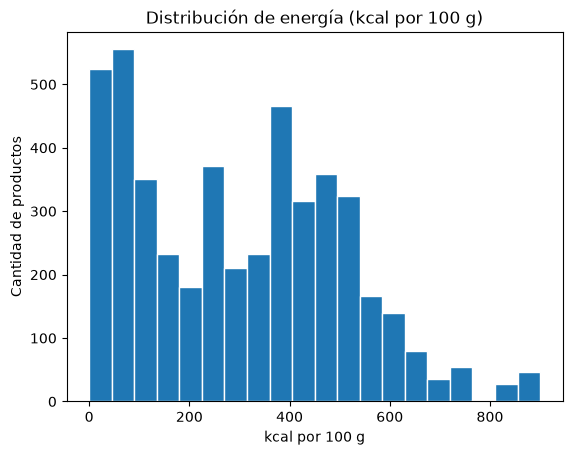

In [ ]:
#Graficamos la distribucion de energia_kcal por cada 100 g.

plt.hist(food_data_set["energia_kcal"].dropna(), bins=20, range=(0, 900), edgecolor="white")
plt.title("Distribución de energía (kcal por 100 g)")
plt.xlabel("kcal por 100 g")
plt.ylabel("Cantidad de productos")
plt.show()

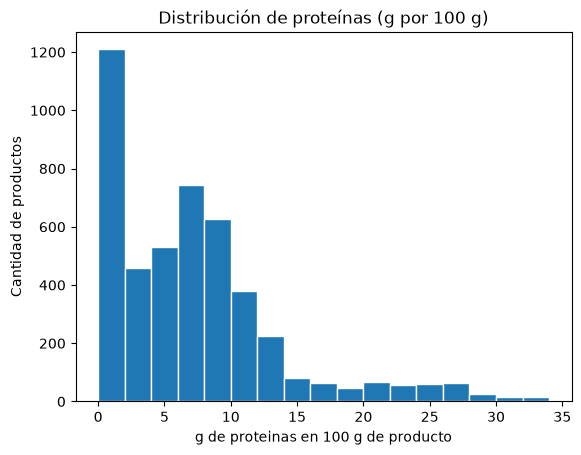

In [ ]:
#Graficamos la distribucion de proteinas por cada 100 g.

datos = food_data_set["proteinas_cada_100g"].dropna()
datos = datos[datos <= 100]
plt.hist(datos, bins=list(range(0, 35, 2)), edgecolor="white")
plt.title("Distribución de proteínas (g por 100 g)")
plt.xlabel("g de proteinas en 100 g de producto")
plt.ylabel("Cantidad de productos")
plt.show()

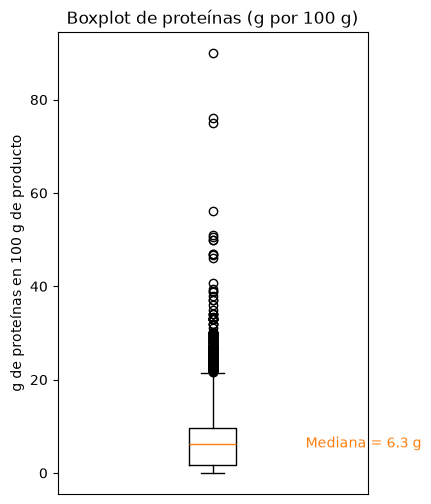

In [ ]:
# Boxplot vertical con el valor de la mediana
mediana = datos.median()

plt.figure(figsize=(4, 6))
plt.boxplot(datos)
plt.text(1.3, mediana, f"Mediana = {mediana:.1f} g", va="center", color="tab:orange")
plt.title("Boxplot de proteínas (g por 100 g)")
plt.ylabel("g de proteínas en 100 g de producto")
plt.xticks([])
plt.show()

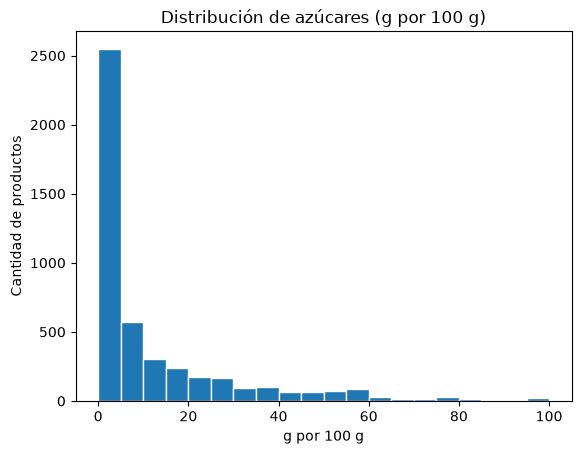

In [ ]:
datos = food_data_set["azucares_cada_100g"].dropna()
datos = datos[datos <= 100]
plt.hist(datos, bins=list(range(0, 101, 5)), edgecolor="white")
plt.title("Distribución de azúcares (g por 100 g)")
plt.xlabel("g por 100 g")
plt.ylabel("Cantidad de productos")
plt.show()

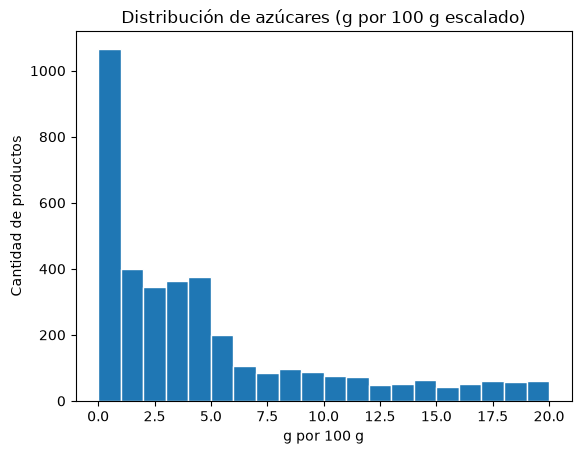

In [ ]:
datos = food_data_set["azucares_cada_100g"].dropna()
datos = datos[datos <= 100]
plt.hist(datos, bins=list(range(0, 21, 1)), edgecolor="white")
plt.title("Distribución de azúcares (g por 100 g escalado)")
plt.xlabel("g por 100 g")
plt.ylabel("Cantidad de productos")
plt.show()

In [ ]:
food_data_set["azucares_cada_100g"].describe()

count    4631.000000
mean       12.368927
std        22.020440
min         0.000000
25%         1.095000
50%         4.300000
75%        16.000000
max       895.000000
Name: azucares_cada_100g, dtype: float64

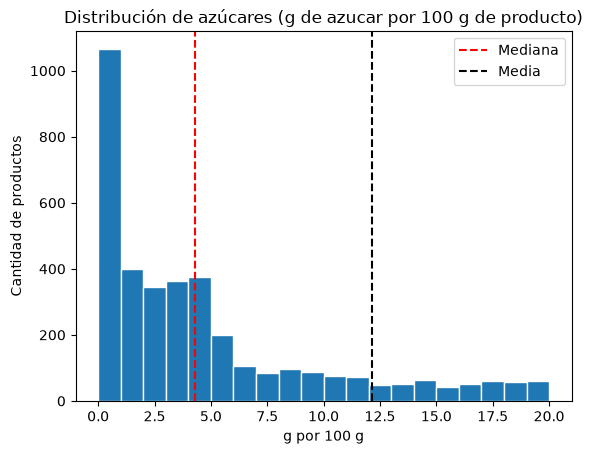

In [ ]:
# Graficamos la distribucion de azucares por cada 100 g.

datos = food_data_set["azucares_cada_100g"].dropna()
datos = datos[datos <= 100]
plt.hist(datos, bins=list(range(0, 21, 1)), edgecolor="white")
plt.title("Distribución de azúcares (g de azucar por 100 g de producto)")
plt.xlabel("g por 100 g")
plt.ylabel("Cantidad de productos")
plt.axvline(datos.median(), color="red", linestyle="--", label="Mediana")
plt.axvline(datos.mean(), color="black", linestyle="--", label="Media")
plt.legend()
plt.show()

In [ ]:
datos = food_data_set["grado_de_procesamiento"].dropna()
print(datos.unique())

# Vemos que valores toma la variable "grado_de_procesamiento" para poder graficar su distribucion.

[3. 1. 4. 2.]


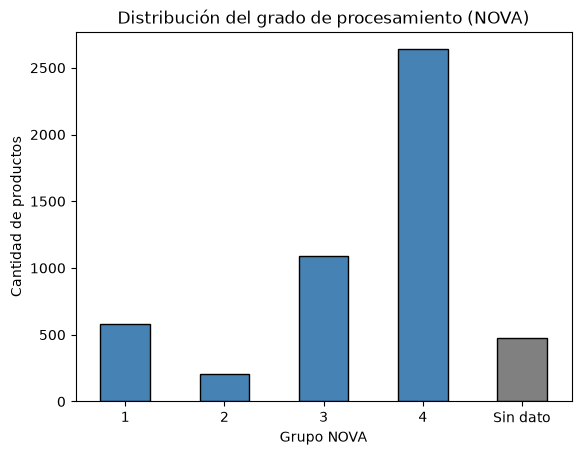

In [ ]:
conteo = food_data_set["grado_de_procesamiento"].value_counts().sort_index()
conteo.index = conteo.index.astype(int)
conteo["Sin dato"] = food_data_set["grado_de_procesamiento"].isna().sum()
colores = ["steelblue", "steelblue", "steelblue", "steelblue", "gray"]

conteo.plot(kind="bar", color=colores, edgecolor="black")
plt.title("Distribución del grado de procesamiento (NOVA)")
plt.xlabel("Grupo NOVA")
plt.ylabel("Cantidad de productos")
plt.xticks(rotation=0)
plt.show()

In [ ]:
datos = food_data_set["impacto_ambiental"].dropna()
print(datos.unique())

# Vemos que valores toma la variable "impacto_ambiental" para poder graficar su distribucion.

<StringArray>
['NOT-APPLICABLE', 'B', 'D', 'UNKNOWN', 'E', 'C', 'A', 'F', 'A-PLUS']
Length: 9, dtype: str


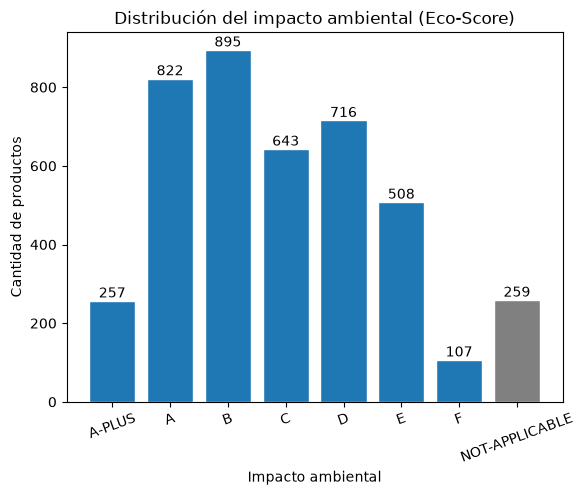

In [ ]:
# Graficamos la distribucion de impacto_ambiental (ecoscore). Excluimos UNKNOWN y dejamos NOT-APPLICABLE al final en gris.

datos = food_data_set["impacto_ambiental"].dropna()
datos = datos[datos != "UNKNOWN"]

orden = ["A-PLUS","A", "B", "C", "D", "E","F", "NOT-APPLICABLE"]
conteo = datos.value_counts().reindex(orden, fill_value=0)

colores = ["tab:blue"] * 7 + ["gray"]

plt.bar(conteo.index, conteo.values, color=colores, edgecolor="white")
plt.title("Distribución del impacto ambiental (Eco-Score)")
plt.xlabel("Impacto ambiental")
plt.ylabel("Cantidad de productos")
plt.xticks(rotation=20)
plt.bar_label(plt.gca().containers[0])
plt.show()

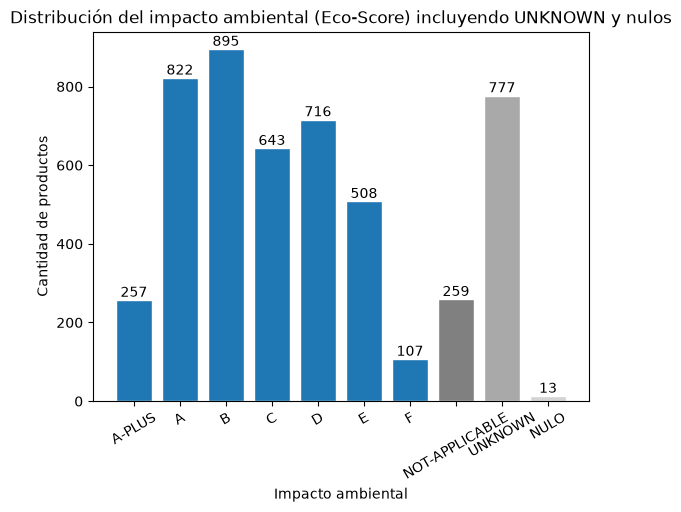

In [ ]:
# Graficamos la distribucion de impacto_ambiental incluyendo UNKNOWN y nulos para ver cuantos hay.

datos = food_data_set["impacto_ambiental"].fillna("NULO")

orden = ["A-PLUS", "A", "B", "C", "D", "E", "F", "NOT-APPLICABLE", "UNKNOWN", "NULO"]
conteo = datos.value_counts().reindex(orden, fill_value=0)

colores = ["tab:blue"] * 7 + ["gray", "darkgray", "lightgray"]

plt.bar(conteo.index, conteo.values, color=colores, edgecolor="white")
plt.title("Distribución del impacto ambiental (Eco-Score) incluyendo UNKNOWN y nulos")
plt.xlabel("Impacto ambiental")
plt.ylabel("Cantidad de productos")
plt.xticks(rotation=30)
plt.bar_label(plt.gca().containers[0])
plt.show()

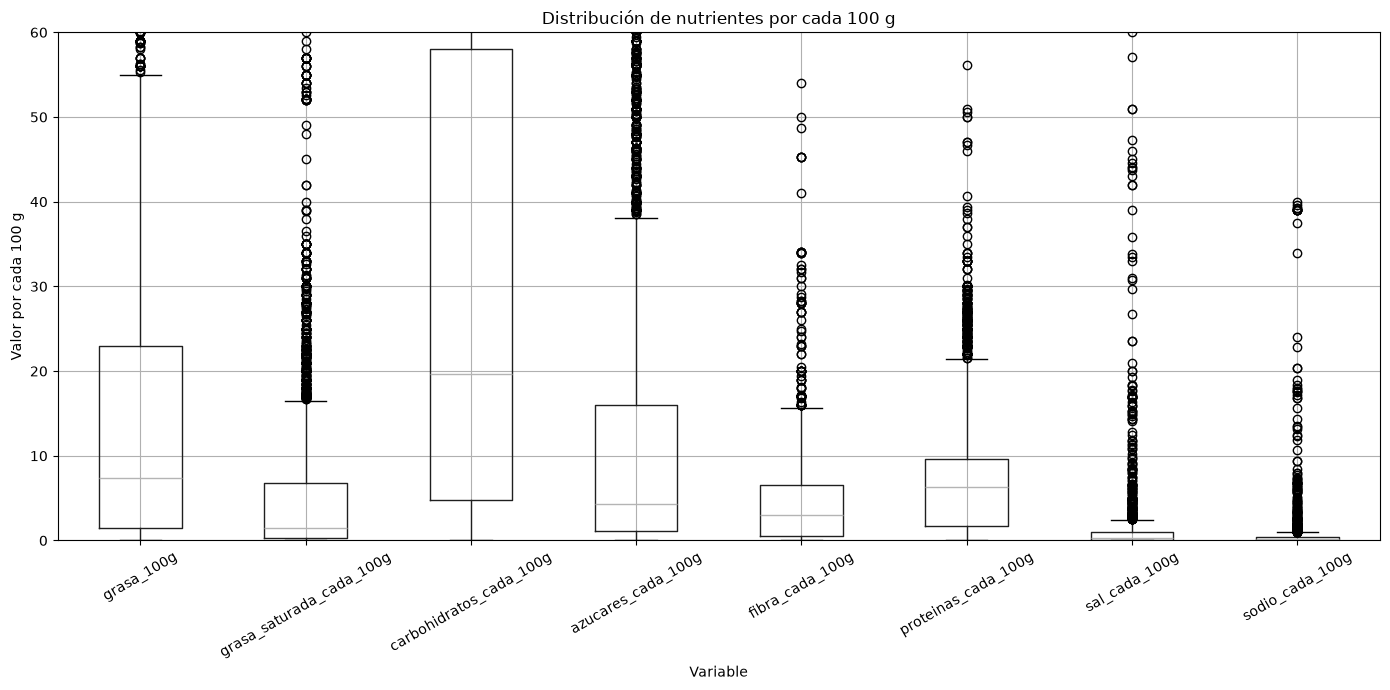

In [ ]:
variables_100g = [
    "grasa_100g",
    "grasa_saturada_cada_100g",
    "carbohidratos_cada_100g",
    "azucares_cada_100g",
    "fibra_cada_100g",
    "proteinas_cada_100g",
    "sal_cada_100g",
    "sodio_cada_100g",
]

fig, ax = plt.subplots(figsize=(14, 7))
food_data_set[variables_100g].boxplot(ax=ax)
ax.set_ylim(0, 60)
ax.set_title("Distribución de nutrientes por cada 100 g")
ax.set_xlabel("Variable")
ax.set_ylabel("Valor por cada 100 g")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

In [ ]:
# Graficamos la distribucion de grasas saturadas agrupando.

datos = food_data_set["grasa_saturada_cada_100g"].dropna()
datos.describe()

count    4617.000000
mean        5.489583
std        12.451133
min         0.000000
25%         0.300000
50%         1.500000
75%         6.800000
max       595.000000
Name: grasa_saturada_cada_100g, dtype: float64

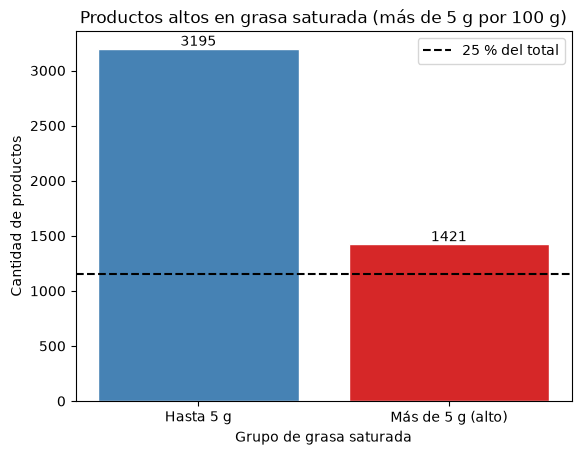

grasa_saturada_cada_100g
Hasta 5 g            3195
Más de 5 g (alto)    1421
Name: count, dtype: int64
Total de productos: 4616
Proporción con más de 5 g: 0.307842287694974


In [ ]:
datos = food_data_set["grasa_saturada_cada_100g"].dropna()
datos = datos[datos <= 100]

bordes = [0, 5, 100]
nombres = ["Hasta 5 g", "Más de 5 g (alto)"]

grupos = pd.cut(datos, bins=bordes, labels=nombres, include_lowest=True)

conteo = grupos.value_counts().sort_index()

colores = ["steelblue", "tab:red"]

plt.bar(conteo.index, conteo.values, color=colores, edgecolor="white")
plt.title("Productos altos en grasa saturada (más de 5 g por 100 g)")
plt.xlabel("Grupo de grasa saturada")
plt.ylabel("Cantidad de productos")
plt.bar_label(plt.gca().containers[0])
plt.axhline(len(datos) * 0.25, color="black", linestyle="--", label="25 % del total")
plt.legend()
plt.show()

print(conteo)
print("Total de productos:", len(datos))
print("Proporción con más de 5 g:", (datos > 5).mean())

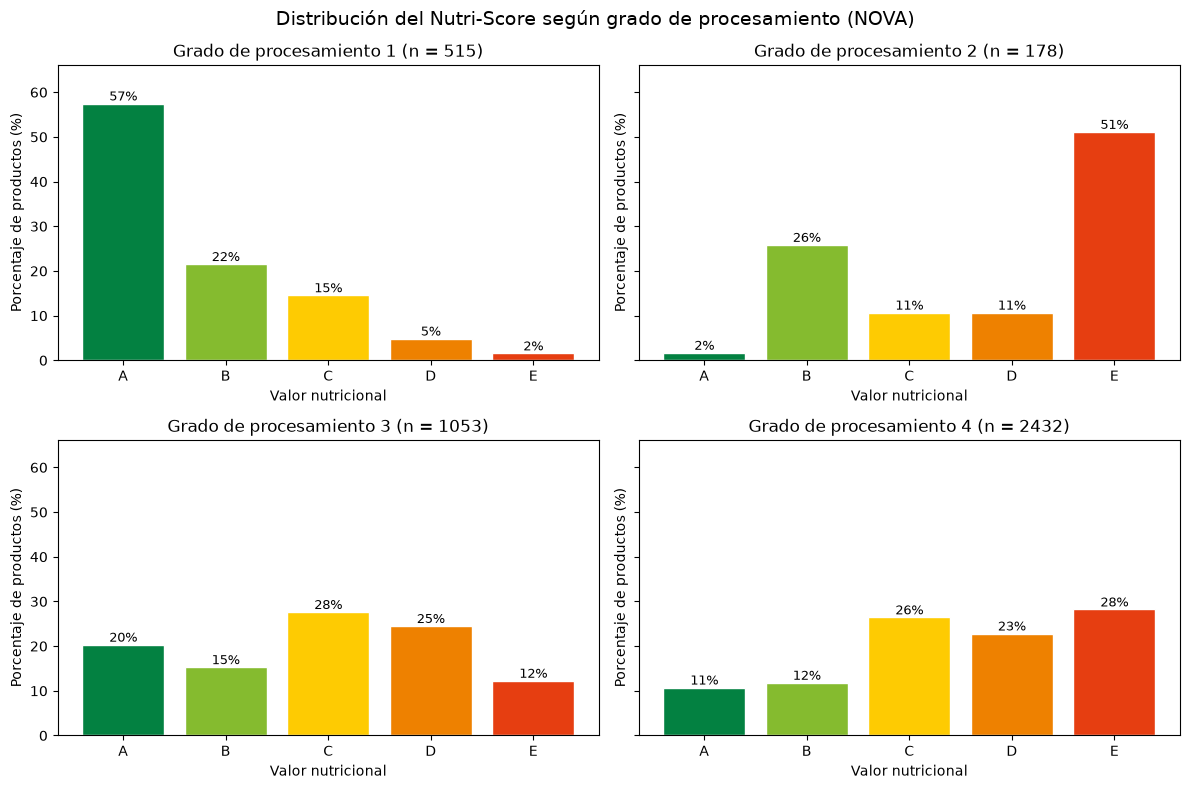

In [ ]:
# Analizamos la relacion entre grado_de_procesamiento (NOVA) y grado_nutricional (Nutri-Score).
# Como ambas son cualitativas ordinales, armamos una tabla de contingencia y hacemos un grafico de barras
# por cada grado NOVA (1 a 4), mostrando como se distribuye el Nutri-Score (A-E) dentro de cada grupo.

datos = food_data_set[["grado_de_procesamiento", "grado_nutricional"]].dropna()
datos = datos[datos["grado_nutricional"].isin(["A", "B", "C", "D", "E"])]
datos["grado_de_procesamiento"] = datos["grado_de_procesamiento"].astype(int)

tabla = pd.crosstab(datos["grado_de_procesamiento"], datos["grado_nutricional"], normalize="index") * 100
tabla = tabla[["A", "B", "C", "D", "E"]]
cantidades = datos["grado_de_procesamiento"].value_counts().sort_index()

colores = ["#038141", "#85BB2F", "#FECB02", "#EE8100", "#E63E11"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)

for ax, nova in zip(axes.flatten(), [1, 2, 3, 4]):
    porcentajes = tabla.loc[nova]
    barras = ax.bar(porcentajes.index, porcentajes.values, color=colores, edgecolor="white")
    ax.bar_label(barras, fmt="%.0f%%", fontsize=9)
    ax.set_title(f"Grado de procesamiento {nova} (n = {cantidades[nova]})")
    ax.set_xlabel("Valor nutricional")
    ax.set_ylabel("Porcentaje de productos (%)")
    ax.set_ylim(0, tabla.values.max() * 1.15)

fig.suptitle("Distribución del Nutri-Score según grado de procesamiento (NOVA)", fontsize=14)
plt.tight_layout()
plt.show()

# Limpieza de variables parte 2

## Eliminamos columnas

In [ ]:
# Guardamos una copia del dataset original con los nombres renombrados.

df_original = food_data_set.copy()

In [ ]:
# Como analizamos previamente la columna "food_type" que renombramos como "tipo_alimento" vemos que tiene un unico valor cargado.

print(food_data_set["tipo_alimento"].unique())

<StringArray>
['Branded/Packaged']
Length: 1, dtype: str


In [ ]:
# Filtramos el dataset para quedarnos solo con las columnas que nos interesan para las hipotesis y ver que valores tienen.

columnas = [
    "nombre_producto", "marca", "categorias",
    "grado_de_procesamiento", "impacto_ambiental", "grado_nutricional",
    "alergenos_declarados",
    "contiene_gluten", "contiene_lacteos", "contiene_frutos_secos",
    "contiene_soja", "contiene_huevo", "contiene_pescado",
    "grasa_saturada_cada_100g",
    "energia_kcal", "grasa_100g", "carbohidratos_cada_100g", "proteinas_cada_100g",
]

food_data_set = food_data_set[columnas]
food_data_set.info()

<class 'pandas.DataFrame'>
RangeIndex: 4997 entries, 0 to 4996
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   nombre_producto           4785 non-null   str    
 1   marca                     4751 non-null   str    
 2   categorias                4913 non-null   str    
 3   grado_de_procesamiento    4522 non-null   float64
 4   impacto_ambiental         4984 non-null   str    
 5   grado_nutricional         4983 non-null   str    
 6   alergenos_declarados      3332 non-null   str    
 7   contiene_gluten           4997 non-null   bool   
 8   contiene_lacteos          4997 non-null   bool   
 9   contiene_frutos_secos     4997 non-null   bool   
 10  contiene_soja             4997 non-null   bool   
 11  contiene_huevo            4997 non-null   bool   
 12  contiene_pescado          4997 non-null   bool   
 13  grasa_saturada_cada_100g  4617 non-null   float64
 14  energia_kcal       

## Limpiamos la columna categorias.

In [ ]:
# Vamos a quedarnos con la primera categoria de cada producto.
# Las categorias con menos de 100 productos las agrupamos en "otros".
# Unificamos la categoria "beverages" y "beverages-and-beverages-preparations" por representar el mismo grupo."
# Los productos sin categorias los dejamos como nulos.
# Eliminamos la etiqueta de "en: " que no aporta ninguna valor estadistico de nuestro interes. Para esto utilizamos expresiones regulares.

cat = food_data_set["categorias"].str.split(",").str[0].str.strip()
cat = cat.str.replace("^en:", "", regex=True)
cat = cat.replace("beverages-and-beverages-preparations", "beverages")

conteo = cat.value_counts()
principales = conteo[conteo >= 100].index

food_data_set["categoria_principal"] = cat.where(cat.isin(principales) | cat.isna(), "otros")

print(food_data_set["categoria_principal"].value_counts(dropna=False))

categoria_principal
plant-based-foods-and-beverages    1881
snacks                              866
dairies                             655
beverages                           616
otros                               467
condiments                          310
breakfasts                          118
NaN                                  84
Name: count, dtype: int64


In [ ]:
# Como ya tenemos la categoria_principal de los alimentos vamos a borrar la columna de categorias.

food_data_set = food_data_set.drop(columns="categorias")
food_data_set.head()

,nombre_producto,marca,grado_de_procesamiento,impacto_ambiental,grado_nutricional,alergenos_declarados,contiene_gluten,contiene_lacteos,contiene_frutos_secos,contiene_soja,contiene_huevo,contiene_pescado,grasa_saturada_cada_100g,energia_kcal,grasa_100g,carbohidratos_cada_100g,proteinas_cada_100g,categoria_principal
0,Sidi Ali,سيدي علي,NaN,NOT-APPLICABLE,A,NaN,False,False,False,False,False,False,0.0,0.0,0.0,4.2,0.0,beverages
1,Perly,Perly,3.0,B,UNKNOWN,"en:banana, en:milk",False,True,False,False,False,False,NaN,97.0,3.0,9.4,8.0,dairies
2,Sidi Ali,Sidi Ali,1.0,NOT-APPLICABLE,A,NaN,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,beverages
3,Eau minérale naturelle,sidi ali,1.0,NOT-APPLICABLE,A,NaN,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,beverages
4,اكوافينا,AQUAFINA,NaN,NOT-APPLICABLE,A,NaN,False,False,False,False,False,False,0.0,0.0,0.0,0.0,0.0,beverages


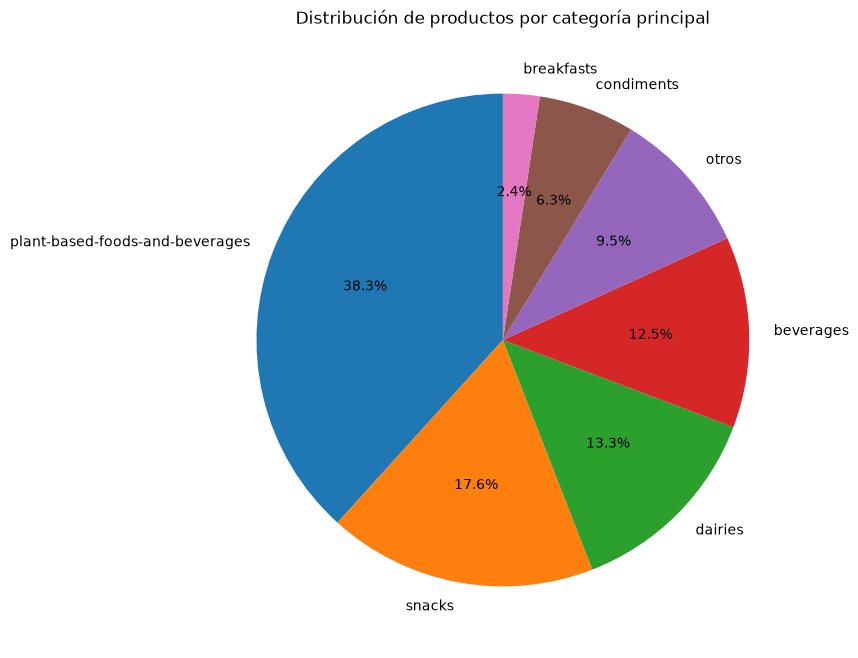

In [ ]:
#Hacemos un grafico de torta para ver la distribucion de las categorias.

conteo_categorias = food_data_set["categoria_principal"].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(conteo_categorias.values, labels=conteo_categorias.index, autopct="%1.1f%%", startangle=90)
plt.title("Distribución de productos por categoría principal")
plt.show()

## Limpiamos la columna de alergenos.

In [ ]:
# Usamos expresiones regulares para sacar el prefijo "en: " de la columna "alergenos_declarados" que no aporta ningun valor estadistico de nuestro interes.
food_data_set["alergenos_declarados"] = food_data_set["alergenos_declarados"].str.replace("en:", "", regex=False)
print (food_data_set["alergenos_declarados"].value_counts(dropna=False))

alergenos_declarados
NaN                                                                   1665
milk                                                                   695
gluten                                                                 630
soybeans                                                               178
gluten, soybeans                                                       131
                                                                      ... 
peanuts, soybeans, select-roasted-peanuts                                1
gluten, suitable-for-vegans                                              1
crustaceans, eggs, fish, gluten, milk, molluscs, mustard, soybeans       1
banana, nuts, sulphur-dioxide-and-sulphites                              1
oatbran                                                                  1
Name: count, Length: 311, dtype: int64


In [ ]:
#Analizamos la columna "alergenos_declarados" para ver que valores tiene y cuantas veces se repite cada uno. Hicimos una separacion por "," para poder contar cada ocurencia de manera individual.


etiquetas = food_data_set["alergenos_declarados"].dropna().str.split(",").explode().str.strip()
print(etiquetas.value_counts().to_string())

alergenos_declarados
gluten                                                                                   1602
milk                                                                                     1510
soybeans                                                                                  851
nuts                                                                                      483
eggs                                                                                      319
peanuts                                                                                   156
celery                                                                                    130
mustard                                                                                   124
fish                                                                                      115
sesame-seeds                                                                              113
sulphur-dioxide-and-sulphites          

In [ ]:
#Para este analisis buscamos informacion sobre los alergenos declarados como obligatorios por la union europea.
# Enmarcamos en oficiales aquellas declaradas y luego hicimos un conteo de las que no entraban en esas categorias

oficiales = [
    "gluten", "crustaceans", "eggs", "fish", "peanuts",
    "soybeans", "milk", "nuts", "celery", "mustard",
    "sesame-seeds", "sulphur-dioxide-and-sulphites", "lupin", "molluscs",
]

descartadas = etiquetas[~etiquetas.isin(oficiales)].value_counts()

print("Cantidad de etiquetas descartadas:", len(descartadas))
for etiqueta, cantidad in descartadas.items():
    print(f"{cantidad:5d}  {etiqueta}")

Cantidad de etiquetas descartadas: 114
   60  fr:avoine
   29  orange
   22  es:avena
   21  none
   18  apple
   13  banana
    9  cereals-with-gluten
    8  chicken
    5  kiwi
    4  pork
    3  lait
    3  fr:alcool
    3  fr:avoine-ou-hybrides-et-produits-a-base-de-ces-cereales
    3  fr:et-produits-a-base-de-ces-cereales
    3  fr:amandes-amygdalus-communis-l
    3  fr:noisettes-corylus-avellana
    2  de:haferbasis
    2  rice
    2  de:sojabasis
    2  noisettes
    2  metabisulphite
    2  fr:sarrasin
    2  celeri
    2  sodium-metabisulphite
    2  mycoprotein
    2  ble
    2  es:trigo-espelta
    2  beef
    2  gelatin
    2  fr:noix-de-pecan-et-produits-a-base-de-noix-de-pecan-carya-illinoiesis-wangenh-k-koch
    2  de:nusskernmischung
    2  de:lait
    2  fr:abricot
    2  orge
    1  de:fruits-à-coque
    1  pt:isento-de-gluten
    1  hazlenuts
    1  cacahuetes
    1  de:crème
    1  palm
    1  fr:laktose
    1  fr:milch
    1  fr:milcheiweiss
    1  fr:weizenstarke


In [ ]:
# Creamos un diccionario de sinonimos para poder traducir los alergenos y unificar valores que representan lo mismo. Por ejemplo "milk" y "milk-protein" son lo mismo, por lo que los unificamos en "milk".

sinonimos = {
    "cereals-with-gluten": "gluten",
    "fr:avoine": "gluten",
    "es:avena": "gluten",
    "de:haferbasis": "gluten",
    "fr:avoine-ou-hybrides-et-produits-a-base-de-ces-cereales": "gluten",
    "fr:et-produits-a-base-de-ces-cereales": "gluten",
    "lait": "milk",
    "fr:amandes-amygdalus-communis-l": "nuts",
    "fr:noisettes-corylus-avellana": "nuts",
    "noisettes": "nuts",
    "de:sojabasis": "soybeans",
    "celeri": "celery",
    "metabisulphite": "sulphur-dioxide-and-sulphites",
    "sodium-metabisulphite": "sulphur-dioxide-and-sulphites",
}

# Vemos el impacto de traducir y unificar los valores sobre nuestro dataset.
# Podemos observar que el porcentaje descartado es del 3.5% lo cual es un numero bastante bajo.

traducidas = etiquetas.map(lambda e: sinonimos.get(e, e))
validas = traducidas.isin(oficiales)

print("Etiquetas totales:", len(traducidas))
print("Etiquetas válidas:", validas.sum())
print("Etiquetas descartadas:", (~validas).sum())
print("Porcentaje descartado:", round((~validas).mean() * 100, 1), "%")

Etiquetas totales: 5853
Etiquetas válidas: 5648
Etiquetas descartadas: 205
Porcentaje descartado: 3.5 %


In [ ]:
# Ahora podemos ver la cantidad de ocurrencias de cada alergeno declarado en el dataset, luego de haber traducido y unificado los valores.

print(traducidas[validas].value_counts())

alergenos_declarados
gluten                           1701
milk                             1513
soybeans                          853
nuts                              491
eggs                              319
peanuts                           156
celery                            132
mustard                           124
fish                              115
sesame-seeds                      113
sulphur-dioxide-and-sulphites      94
crustaceans                        20
molluscs                           10
lupin                               7
Name: count, dtype: int64


In [ ]:
# Cuenta, por producto, los alérgenos regulados distintos declarados.
# Las etiquetas se traducen con el diccionario de sinónimos y se descartan
# las que no corresponden a alérgenos regulados. Sin información = 0.

def contar_alergenos(texto):
    if pd.isna(texto):
        return 0
    etiquetas = {sinonimos.get(e.strip(), e.strip()) for e in texto.split(",")}
    return sum(e in oficiales for e in etiquetas)

# Creamos una columna nueva para contar la cantidad de alergenos declarados por producto. Para esto usamos la funcion contar_alergenos que definimos previamente.
food_data_set["cantidad_alergenos"] = food_data_set["alergenos_declarados"].apply(contar_alergenos)

print(food_data_set["cantidad_alergenos"].value_counts().sort_index())

food_data_set.head()

cantidad_alergenos
0     1741
1     1948
2      694
3      397
4      156
5       38
6        9
7       11
8        2
11       1
Name: count, dtype: int64


,nombre_producto,marca,grado_de_procesamiento,impacto_ambiental,grado_nutricional,alergenos_declarados,contiene_gluten,contiene_lacteos,contiene_frutos_secos,contiene_soja,contiene_huevo,contiene_pescado,grasa_saturada_cada_100g,energia_kcal,grasa_100g,carbohidratos_cada_100g,proteinas_cada_100g,categoria_principal,cantidad_alergenos
0,Sidi Ali,سيدي علي,NaN,NOT-APPLICABLE,A,NaN,False,False,False,False,False,False,0.0,0.0,0.0,4.2,0.0,beverages,0
1,Perly,Perly,3.0,B,UNKNOWN,"banana, milk",False,True,False,False,False,False,NaN,97.0,3.0,9.4,8.0,dairies,1
2,Sidi Ali,Sidi Ali,1.0,NOT-APPLICABLE,A,NaN,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,beverages,0
3,Eau minérale naturelle,sidi ali,1.0,NOT-APPLICABLE,A,NaN,False,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,beverages,0
4,اكوافينا,AQUAFINA,NaN,NOT-APPLICABLE,A,NaN,False,False,False,False,False,False,0.0,0.0,0.0,0.0,0.0,beverages,0


In [ ]:
food_data_set[["alergenos_declarados", "cantidad_alergenos"]].sample(10, random_state=42)

,alergenos_declarados,cantidad_alergenos
84,NaN,0
4374,celery,1
1497,NaN,0
653,"gluten, milk, soybeans",3
877,"nuts, soybeans, fi:kuoritut-soijapavut",2
4880,gluten,1
157,milk,1
3611,"gluten, milk, nuts, soybeans",4
751,gluten,1
2822,NaN,0


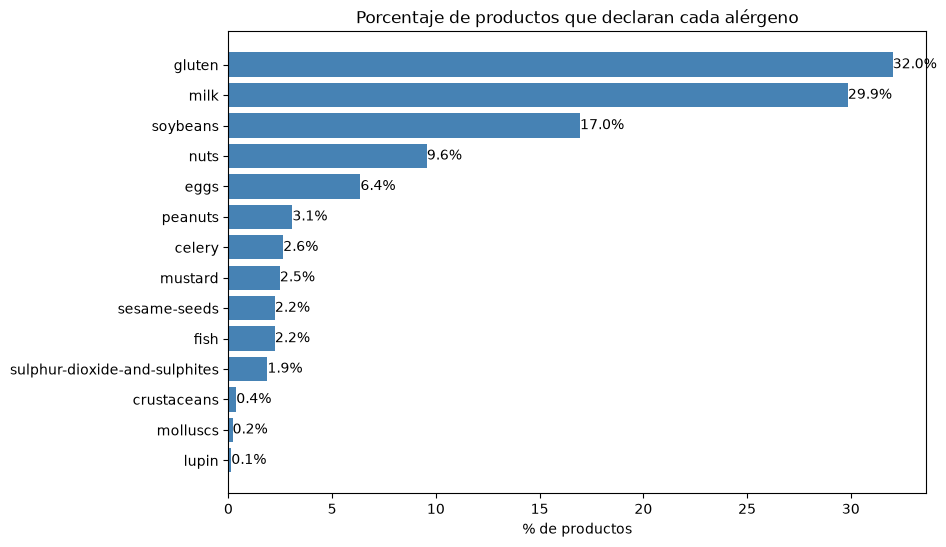

In [ ]:
#Hacemos un grafico de barras para ver la distribucion de los alergenos.

validas = traducidas[traducidas.isin(oficiales)]
productos_por_alergeno = validas.reset_index().drop_duplicates()["alergenos_declarados"].value_counts()

porcentaje = productos_por_alergeno / len(food_data_set) * 100
porcentaje = porcentaje.sort_values()

plt.figure(figsize=(9, 6))
plt.barh(porcentaje.index, porcentaje.values, color="steelblue")
plt.bar_label(plt.gca().containers[0], fmt="%.1f%%")
plt.title("Porcentaje de productos que declaran cada alérgeno")
plt.xlabel("% de productos")
plt.show()

## Buscamos filas duplicadas

In [ ]:
# Podemos observar que hay 74 filas que estan duplicadas. 
# Vemos en el df_original hay solo 38 duplicadas. por lo tanto miramos las diferencias.

print("Duplicados en las columnas actuales:", food_data_set.duplicated().sum())
print("Duplicados en el dataset original:", df_original.duplicated().sum())

solo_actuales = food_data_set.duplicated(keep=False) & ~df_original.duplicated(keep=False)
df_original[solo_actuales].sort_values("nombre_producto").head(10)

Duplicados en las columnas actuales: 74
Duplicados en el dataset original: 38


,nombre_producto,marca,categorias,ingredientes,grado_nutricional,grado_de_procesamiento,impacto_ambiental,alergenos_declarados,energia_kcal,grasa_100g,...,proteinas_cada_100g,sal_cada_100g,sodio_cada_100g,contiene_gluten,contiene_lacteos,contiene_frutos_secos,contiene_soja,contiene_huevo,contiene_pescado,tipo_alimento
3860,Coca Cola,Coca-Cola,"en:beverages-and-beverages-preparations, en:be...","acqua, zucchero, anidride carbonica, colorante...",E,4.0,NOT-APPLICABLE,NaN,42.0,0.00,...,0.0,0.000,0.0000,False,False,False,False,False,False,Branded/Packaged
204,Coca Cola,Coca-Cola,"en:beverages-and-beverages-preparations, en:be...","water, sugar, carbonic acid, e150d, e338, natu...",E,4.0,NOT-APPLICABLE,NaN,42.0,0.00,...,0.0,0.000,0.0000,False,False,False,False,False,False,Branded/Packaged
2371,Crunchy Nut,Kellogg's,"en:plant-based-foods-and-beverages, en:plant-b...","Maize, sugar, peanuts (6%), barley malt extrac...",D,3.0,D,"en:gluten, en:peanuts",397.0,4.67,...,6.0,0.767,0.3070,True,False,True,False,False,False,Branded/Packaged
4937,Crunchy Nut,Kellogg's,"en:plant-based-foods-and-beverages, en:plant-b...","Maize, sugar, peanuts (6%), barley malt extrac...",D,3.0,D,"en:gluten, en:peanuts",397.0,4.67,...,6.0,0.750,0.3000,True,False,True,False,False,False,Branded/Packaged
2909,Ferrero Rocher,Ferrero,"en:snacks, en:sweet-snacks, en:cocoa-and-its-p...","MILK chocolate 30% (sugar, cocoa butter, cocoa...",E,4.0,UNKNOWN,"en:gluten, en:milk, en:nuts, en:soybeans",603.0,42.70,...,8.2,0.153,0.0612,True,True,True,True,False,False,Branded/Packaged
778,Ferrero Rocher,Ferrero,"en:snacks, en:sweet-snacks, en:cocoa-and-its-p...","Chocolat au LAIT 30% (sucre, beurre de cacao, ...",E,4.0,UNKNOWN,"en:gluten, en:milk, en:nuts, en:soybeans",603.0,42.70,...,8.2,0.150,0.0600,True,True,True,True,False,False,Branded/Packaged
4305,Guacamole,Hacendado,"en:plant-based-foods-and-beverages, en:plant-b...","Aguacate (95%), sal, cebolla deshidratada, jal...",C,4.0,C,NaN,149.0,13.70,...,1.9,1.500,0.6000,False,False,False,False,False,False,Branded/Packaged
541,Guacamole,Hacendado,"en:plant-based-foods-and-beverages, en:plant-b...","avocado (95%), salt, dehydrated onion, jalapeñ...",C,4.0,C,NaN,149.0,13.70,...,1.9,1.500,0.6000,False,False,False,False,False,False,Branded/Packaged
4411,Huile d'Olive Vierge Extra,Puget,"en:plant-based-foods-and-beverages, en:plant-b...",Huile d'olive de catégorie supérieure obtenue ...,B,2.0,D,NaN,900.0,100.00,...,0.0,0.000,0.0000,False,False,False,False,False,False,Branded/Packaged
2130,Huile d'Olive Vierge Extra,Puget,"en:plant-based-foods-and-beverages, en:plant-b...",Huile d'olive,B,2.0,D,NaN,900.0,100.00,...,0.0,0.000,0.0000,False,False,False,False,False,False,Branded/Packaged


In [ ]:
# Procedemos a borrar duplicados.

filas_antes = len(food_data_set)
food_data_set = food_data_set[~food_data_set.duplicated()]
print("Filas eliminadas:", filas_antes - len(food_data_set))
print("Filas restantes:", len(food_data_set))

Filas eliminadas: 74
Filas restantes: 4923


## Modificamos tipos de datos

In [ ]:
# Convertimos las columnas de "contiene_x" a tipo entero. 1 si tiene, 0 si no tiene.

columnas_contiene = ["contiene_gluten", "contiene_lacteos", "contiene_frutos_secos",
                     "contiene_soja", "contiene_huevo", "contiene_pescado"]
food_data_set[columnas_contiene] = food_data_set[columnas_contiene].astype(int)

food_data_set.info()

<class 'pandas.DataFrame'>
Index: 4923 entries, 0 to 4996
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   nombre_producto           4764 non-null   str    
 1   marca                     4730 non-null   str    
 2   grado_de_procesamiento    4497 non-null   float64
 3   impacto_ambiental         4922 non-null   str    
 4   grado_nutricional         4921 non-null   str    
 5   alergenos_declarados      3316 non-null   str    
 6   contiene_gluten           4923 non-null   int64  
 7   contiene_lacteos          4923 non-null   int64  
 8   contiene_frutos_secos     4923 non-null   int64  
 9   contiene_soja             4923 non-null   int64  
 10  contiene_huevo            4923 non-null   int64  
 11  contiene_pescado          4923 non-null   int64  
 12  grasa_saturada_cada_100g  4596 non-null   float64
 13  energia_kcal              4661 non-null   float64
 14  grasa_100g              

In [ ]:
# Convertimos la columna "grado_de_procesamiento" NOVA a tipo entero. 1, 2, 3 o 4 si tiene valor, NaN si no tiene.
# Antes estaba en float 1.0


food_data_set["grado_de_procesamiento"] = food_data_set["grado_de_procesamiento"].astype("Int64")

food_data_set.info()

<class 'pandas.DataFrame'>
Index: 4923 entries, 0 to 4996
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   nombre_producto           4764 non-null   str    
 1   marca                     4730 non-null   str    
 2   grado_de_procesamiento    4497 non-null   Int64  
 3   impacto_ambiental         4922 non-null   str    
 4   grado_nutricional         4921 non-null   str    
 5   alergenos_declarados      3316 non-null   str    
 6   contiene_gluten           4923 non-null   int64  
 7   contiene_lacteos          4923 non-null   int64  
 8   contiene_frutos_secos     4923 non-null   int64  
 9   contiene_soja             4923 non-null   int64  
 10  contiene_huevo            4923 non-null   int64  
 11  contiene_pescado          4923 non-null   int64  
 12  grasa_saturada_cada_100g  4596 non-null   float64
 13  energia_kcal              4661 non-null   float64
 14  grasa_100g              

In [ ]:
#Creamos una columna nueva para el grado nutricional que es numerica y va del 1 al 5. Esto nos va a servir para luego analizar las hipotesis.
# Los valores que no están en el diccionario (UNKNOWN, NOT-APPLICABLE) quedan como nulos.

orden_nutri = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5}
food_data_set["grado_nutricional_numerico"] = food_data_set["grado_nutricional"].map(orden_nutri)
food_data_set["grado_nutricional_numerico"] = food_data_set["grado_nutricional_numerico"].astype("Int64")

food_data_set.head()

,nombre_producto,marca,grado_de_procesamiento,impacto_ambiental,grado_nutricional,alergenos_declarados,contiene_gluten,contiene_lacteos,contiene_frutos_secos,contiene_soja,contiene_huevo,contiene_pescado,grasa_saturada_cada_100g,energia_kcal,grasa_100g,carbohidratos_cada_100g,proteinas_cada_100g,categoria_principal,cantidad_alergenos,grado_nutricional_numerico
0,Sidi Ali,سيدي علي,<NA>,NOT-APPLICABLE,A,NaN,0,0,0,0,0,0,0.0,0.0,0.0,4.2,0.0,beverages,0,1
1,Perly,Perly,3,B,UNKNOWN,"banana, milk",0,1,0,0,0,0,NaN,97.0,3.0,9.4,8.0,dairies,1,<NA>
2,Sidi Ali,Sidi Ali,1,NOT-APPLICABLE,A,NaN,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,beverages,0,1
3,Eau minérale naturelle,sidi ali,1,NOT-APPLICABLE,A,NaN,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,beverages,0,1
4,اكوافينا,AQUAFINA,<NA>,NOT-APPLICABLE,A,NaN,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,beverages,0,1


In [ ]:
# Columna numérica del Eco-Score (A-PLUS=1 ... F=7), donde un número mayor indica mayor impacto ambiental.
# Los valores que no están en el diccionario (UNKNOWN, NOT-APPLICABLE) quedan como nulos.

orden_eco = {"A-PLUS": 1, "A": 2, "B": 3, "C": 4, "D": 5, "E": 6, "F": 7}
food_data_set["impacto_ambiental_numerico"] = food_data_set["impacto_ambiental"].map(orden_eco)
food_data_set["impacto_ambiental_numerico"] = food_data_set["impacto_ambiental_numerico"].astype("Int64")

food_data_set.head()

,nombre_producto,marca,grado_de_procesamiento,impacto_ambiental,grado_nutricional,alergenos_declarados,contiene_gluten,contiene_lacteos,contiene_frutos_secos,contiene_soja,...,contiene_pescado,grasa_saturada_cada_100g,energia_kcal,grasa_100g,carbohidratos_cada_100g,proteinas_cada_100g,categoria_principal,cantidad_alergenos,grado_nutricional_numerico,impacto_ambiental_numerico
0,Sidi Ali,سيدي علي,<NA>,NOT-APPLICABLE,A,NaN,0,0,0,0,...,0,0.0,0.0,0.0,4.2,0.0,beverages,0,1,<NA>
1,Perly,Perly,3,B,UNKNOWN,"banana, milk",0,1,0,0,...,0,NaN,97.0,3.0,9.4,8.0,dairies,1,<NA>,3
2,Sidi Ali,Sidi Ali,1,NOT-APPLICABLE,A,NaN,0,0,0,0,...,0,NaN,NaN,NaN,NaN,NaN,beverages,0,1,<NA>
3,Eau minérale naturelle,sidi ali,1,NOT-APPLICABLE,A,NaN,0,0,0,0,...,0,NaN,NaN,NaN,NaN,NaN,beverages,0,1,<NA>
4,اكوافينا,AQUAFINA,<NA>,NOT-APPLICABLE,A,NaN,0,0,0,0,...,0,0.0,0.0,0.0,0.0,0.0,beverages,0,1,<NA>


### Eliminamos valores imposibles de las columnas de kcalorias, gasa saturada, carbohidratos, proteinas y grasa

In [ ]:
# Cantidad de valores físicamente imposibles: más de 100 g de un nutriente
# en 100 g de producto, o más de 900 kcal (máximo correspondiente a grasa pura).

print("Energía > 900:", (food_data_set["energia_kcal"] > 900).sum())
print("Grasa > 100:", (food_data_set["grasa_100g"] > 100).sum())
print("Grasa saturada > 100:", (food_data_set["grasa_saturada_cada_100g"] > 100).sum())
print("Carbohidratos > 100:", (food_data_set["carbohidratos_cada_100g"] > 100).sum())
print("Proteínas > 100:", (food_data_set["proteinas_cada_100g"] > 100).sum())

Energía > 900: 3
Grasa > 100: 2
Grasa saturada > 100: 1
Carbohidratos > 100: 2
Proteínas > 100: 1


In [ ]:
# Ponemos en NONE aquellas filas que no cumplen con el maximo establecido

food_data_set.loc[food_data_set["energia_kcal"] > 900, "energia_kcal"] = None
food_data_set.loc[food_data_set["grasa_100g"] > 100, "grasa_100g"] = None
food_data_set.loc[food_data_set["grasa_saturada_cada_100g"] > 100, "grasa_saturada_cada_100g"] = None
food_data_set.loc[food_data_set["carbohidratos_cada_100g"] > 100, "carbohidratos_cada_100g"] = None
food_data_set.loc[food_data_set["proteinas_cada_100g"] > 100, "proteinas_cada_100g"] = None

In [ ]:
#Volvemos a hacer el print para chequear que no haya valores imposibles.

print("Energía > 900:", (food_data_set["energia_kcal"] > 900).sum())
print("Grasa > 100:", (food_data_set["grasa_100g"] > 100).sum())
print("Grasa saturada > 100:", (food_data_set["grasa_saturada_cada_100g"] > 100).sum())
print("Carbohidratos > 100:", (food_data_set["carbohidratos_cada_100g"] > 100).sum())
print("Proteínas > 100:", (food_data_set["proteinas_cada_100g"] > 100).sum())

Energía > 900: 0
Grasa > 100: 0
Grasa saturada > 100: 0
Carbohidratos > 100: 0
Proteínas > 100: 0


# Hipotesis Univariadas

## Mas del 50% del total de los alimentos son ultraprocesados (grado_de_procesamiento 4)

In [ ]:
# Vamos a chequear la variable "grado_de_procesamiento" es una variable cualitativa ordinal.
# Imprimimos los valores para tener una referencia de la cantidad de productos vs los productos ultraprocesados.

from scipy import stats

datos_h1 = food_data_set["grado_de_procesamiento"].dropna()

n = len(datos_h1)
k = (datos_h1 == 4).sum()

print("Productos con dato de NOVA:", n)
print("Productos ultraprocesados (NOVA 4):", k)
print("Proporción observada:", round(k / n, 3))

Productos con dato de NOVA: 4497
Productos ultraprocesados (NOVA 4): 2624
Proporción observada: 0.584


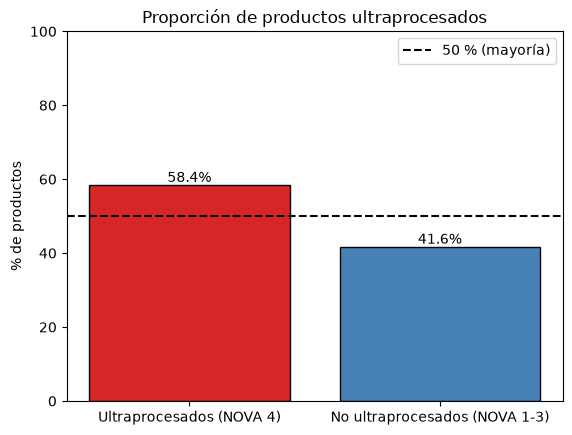

In [ ]:
# El grafico confirma lo que vimos en el print anterior.

proporciones = [k / n * 100, (n - k) / n * 100]
etiquetas = ["Ultraprocesados (NOVA 4)", "No ultraprocesados (NOVA 1-3)"]

plt.bar(etiquetas, proporciones, color=["tab:red", "steelblue"], edgecolor="black")
plt.bar_label(plt.gca().containers[0], fmt="%.1f%%")
plt.axhline(50, color="black", linestyle="--", label="50 % (mayoría)")
plt.ylim(0, 100)
plt.title("Proporción de productos ultraprocesados")
plt.ylabel("% de productos")
plt.legend()
plt.show()

In [ ]:
# Hacemos un test chi cuadrado para comprobar la hipotesis.

observadas = [k, n - k]
esperadas = [n * 0.5, n * 0.5]

resultado_chi = stats.chisquare(observadas, esperadas)
print("p-valor:", resultado_chi.pvalue)
print("Grado de confianza 95%")

p-valor: 4.124520264919065e-29
Grado de confianza 95%


In [ ]:
# Como obtuvimos un valor chico de "p < 0.05" rechazamos la H0 que nos decia que el 50% o menos de los alimentos eran ultraprocesados.
# Es decir aceptamos H1, el 50% o mas de los alimentos, son ultraprocesados. Confirma las observaciones que hicimos con el grafico y analiticas.

## La proporción de productos catalogados como "altos en grasas saturadas" (más de 5 g de grasa saturada por cada 100 g de producto) en la población de referencia es superior al 25%.

In [ ]:
# Graficamos la variable "grasa_saturada_cada_100g" para ver como se distribuyen sus datos.

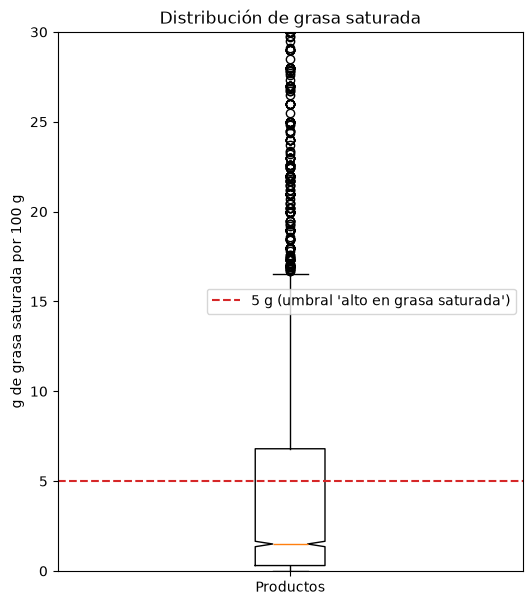

Productos con dato: 4595
Tercer cuartil (Q3): 6.8


In [ ]:
datos_a = food_data_set["grasa_saturada_cada_100g"].dropna()

plt.figure(figsize=(6, 7))
plt.boxplot(datos_a, notch=True)
plt.axhline(5, color="tab:red", linestyle="--", label="5 g (umbral 'alto en grasa saturada')")
plt.ylim(0, 30)
plt.title("Distribución de grasa saturada")
plt.ylabel("g de grasa saturada por 100 g")
plt.xticks([1], ["Productos"])
plt.legend()
plt.show()

print("Productos con dato:", len(datos_a))
print("Tercer cuartil (Q3):", datos_a.quantile(0.75))

In [ ]:
# Con el grafico observamos que el 25% de los productos tienen 6,8g de grasa o mas. A esto le sumamos lo que esta entre 5g y 6,8g por lo tanto visualmente, la hipotesis pareciera ser verdadera.

In [ ]:
# Resolviendo la operacion matematica de "alimentos con mas de 5g / total de alimentos" tambien observamos que la proporcion es del 30%.
# Otra evidencia de que la hipotesis pareciera ser verdadera.

k_a = (datos_a > 5).sum()
n_a = len(datos_a)
print("Productos con más de 5 g:", k_a)
print("Proporción:", round(k_a / n_a, 3))

Productos con más de 5 g: 1413
Proporción: 0.308


In [ ]:
k_a = (datos_a > 5).sum()
n_a = len(datos_a)

observadas_a = [k_a, n_a - k_a]
esperadas_a = [n_a * 0.25, n_a * 0.75]

resultado_a = stats.chisquare(observadas_a, esperadas_a)

print("Productos con más de 5 g:", k_a, "de", n_a)
print("Proporción observada:", round(k_a / n_a, 3))
print("p-valor:", resultado_a.pvalue)

Productos con más de 5 g: 1413 de 4595
Proporción observada: 0.308
p-valor: 2.2028244093854935e-19


In [ ]:
# Como el p valor dio < 0.05 rechazamos H0 que decia que "La proporción de productos con más de 5 g de grasa saturada es menor o igual al 25%"
# Por lo tanto verificamos que mas del 25% de los productos tienen mas de 5g de grasas saturadas cada 100g.

# Hipotesis Bivariadas

## Los alimentos con alto grado de procesamiento tienen mas impacto ambiental

In [ ]:
food_data_set.info()

<class 'pandas.DataFrame'>
Index: 4923 entries, 0 to 4996
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   nombre_producto             4764 non-null   str    
 1   marca                       4730 non-null   str    
 2   grado_de_procesamiento      4497 non-null   Int64  
 3   impacto_ambiental           4922 non-null   str    
 4   grado_nutricional           4921 non-null   str    
 5   alergenos_declarados        3316 non-null   str    
 6   contiene_gluten             4923 non-null   int64  
 7   contiene_lacteos            4923 non-null   int64  
 8   contiene_frutos_secos       4923 non-null   int64  
 9   contiene_soja               4923 non-null   int64  
 10  contiene_huevo              4923 non-null   int64  
 11  contiene_pescado            4923 non-null   int64  
 12  grasa_saturada_cada_100g    4595 non-null   float64
 13  energia_kcal                4658 non-null   float

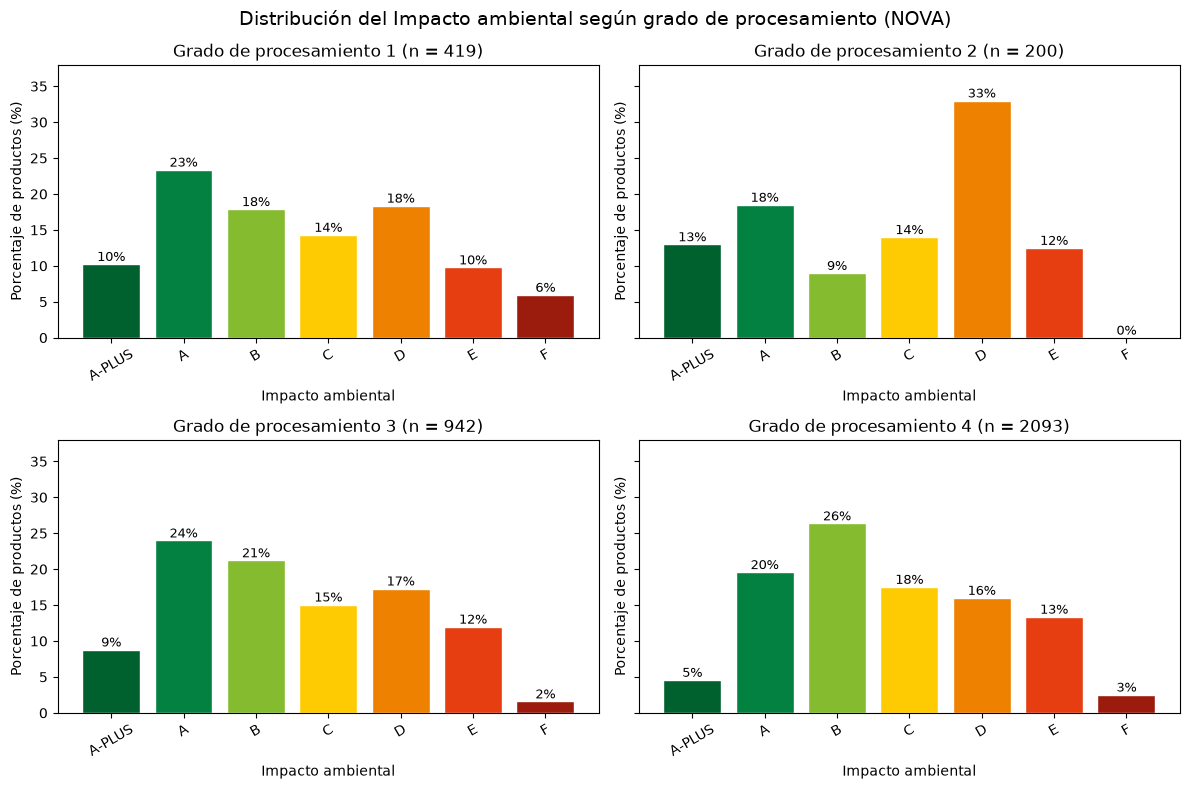

In [ ]:
datos_h2 = food_data_set[["grado_de_procesamiento", "impacto_ambiental_numerico"]].dropna()
datos_h2["grado_de_procesamiento"] = datos_h2["grado_de_procesamiento"].astype(int)
datos_h2["impacto_ambiental_numerico"] = datos_h2["impacto_ambiental_numerico"].astype(int)

tabla_h2 = pd.crosstab(datos_h2["grado_de_procesamiento"], datos_h2["impacto_ambiental_numerico"], normalize="index") * 100
tabla_h2 = tabla_h2.reindex(columns=range(1, 8), fill_value=0)
tabla_h2.columns = ["A-PLUS", "A", "B", "C", "D", "E", "F"]

cantidades_h2 = datos_h2["grado_de_procesamiento"].value_counts().sort_index()

colores_eco = ["#00602E", "#038141", "#85BB2F", "#FECB02", "#EE8100", "#E63E11", "#9B1C0C"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)

for ax, nova in zip(axes.flatten(), [1, 2, 3, 4]):
    porcentajes = tabla_h2.loc[nova]
    barras = ax.bar(porcentajes.index, porcentajes.values, color=colores_eco, edgecolor="white")
    ax.bar_label(barras, fmt="%.0f%%", fontsize=9)
    ax.set_title(f"Grado de procesamiento {nova} (n = {cantidades_h2[nova]})")
    ax.set_xlabel("Impacto ambiental")
    ax.set_ylabel("Porcentaje de productos (%)")
    ax.set_ylim(0, tabla_h2.values.max() * 1.15)
    ax.tick_params(axis="x", rotation=30)

fig.suptitle("Distribución del Impacto ambiental según grado de procesamiento (NOVA)", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
g1 = datos_h2.loc[datos_h2["grado_de_procesamiento"] == 1, "impacto_ambiental_numerico"]
g2 = datos_h2.loc[datos_h2["grado_de_procesamiento"] == 2, "impacto_ambiental_numerico"]
g3 = datos_h2.loc[datos_h2["grado_de_procesamiento"] == 3, "impacto_ambiental_numerico"]
g4 = datos_h2.loc[datos_h2["grado_de_procesamiento"] == 4, "impacto_ambiental_numerico"]

print("NOVA 1:", stats.shapiro(g1).pvalue)
print("NOVA 2:", stats.shapiro(g2).pvalue)
print("NOVA 3:", stats.shapiro(g3).pvalue)
print("NOVA 4:", stats.shapiro(g4).pvalue)

NOVA 1: 4.318063847407762e-13
NOVA 2: 1.309854403790771e-11
NOVA 3: 8.537232475206137e-21
NOVA 4: 2.2101518247092933e-29


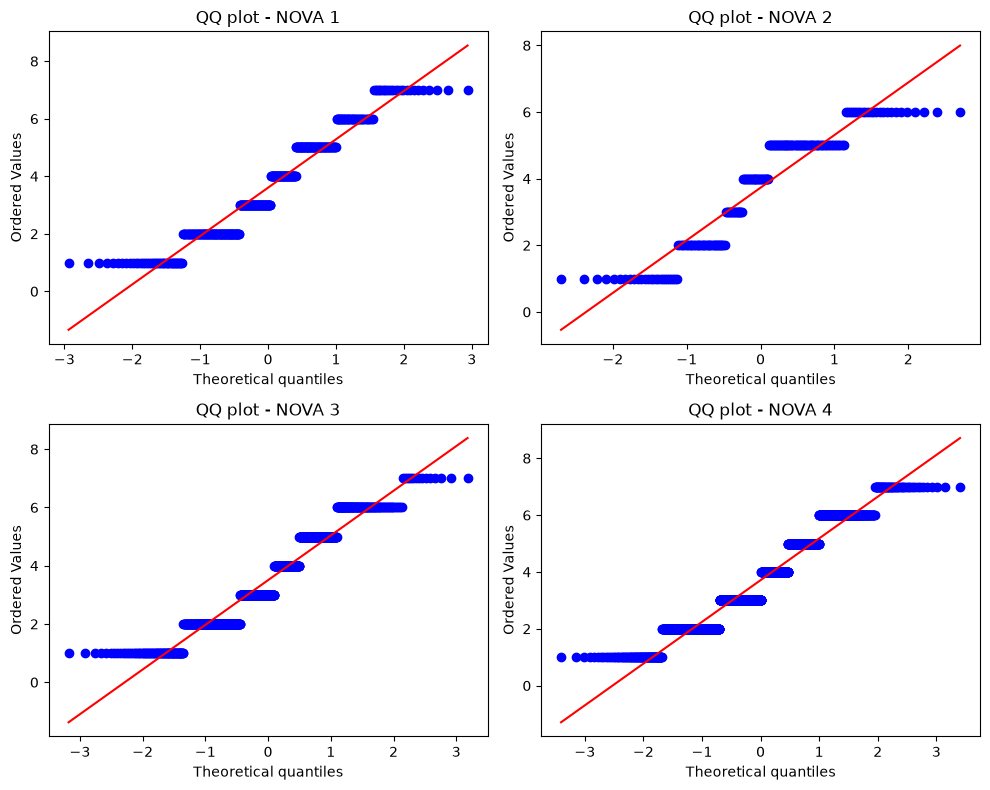

In [ ]:
#Graficamos los QQ plot para chequear de manera grafica que los grupos no siguen una distribucion normal.
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

stats.probplot(g1, dist="norm", plot=axes[0, 0])
axes[0, 0].set_title("QQ plot - NOVA 1")

stats.probplot(g2, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("QQ plot - NOVA 2")

stats.probplot(g3, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("QQ plot - NOVA 3")

stats.probplot(g4, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("QQ plot - NOVA 4")

plt.tight_layout()
plt.show()

In [ ]:
# Corremos el test de LEVENE para chequear HOMOSEDASTISIDAD.
# Como el p valor es < 0.05 podemos afirmar que los grupos no son homosedasticos, es decir las varianzas no son semenajntes.

resultado_levene = stats.levene(g1, g2, g3, g4)

print("p-valor:", resultado_levene.pvalue)

p-valor: 0.002298465516508353


In [ ]:
# Corremos el test de Kruskall Wallys para ver si "H0: El impacto ambiental es igual en los 4 grupos" "H1: Es distinto"
# Si rechazamos H0 hay que ver si respeta el orden esperando

resultado_kw = stats.kruskal(g1, g2, g3, g4)

print("p-valor:", resultado_kw.pvalue)

p-valor: 0.003954318553869923


In [ ]:
# Como rechazamos la hipotesis de que todas sean igual, vemos el orden de la media de impacto ambiental para cada grado de procesamiento.
for nombre, grupo in [("NOVA 1", g1), ("NOVA 2", g2), ("NOVA 3", g3), ("NOVA 4", g4)]:
    print(f"{nombre}: mediana = {grupo.median()}, media = {round(grupo.mean(), 2)}")

NOVA 1: mediana = 3.0, media = 3.6
NOVA 2: mediana = 4.0, media = 3.73
NOVA 3: mediana = 3.0, media = 3.5
NOVA 4: mediana = 3.0, media = 3.71


In [ ]:
# Sorprendentemente el grupo que mas impacto ambiental tiene es el de NOVA 2, y el que menos tiene es el de NOVA 3.

## El grado de procesamiento industrial de un alimento está asociado con la calificación nutricional Nutri-Score que recibe, de manera que los productos más procesados presentan calificaciones más desfavorables.

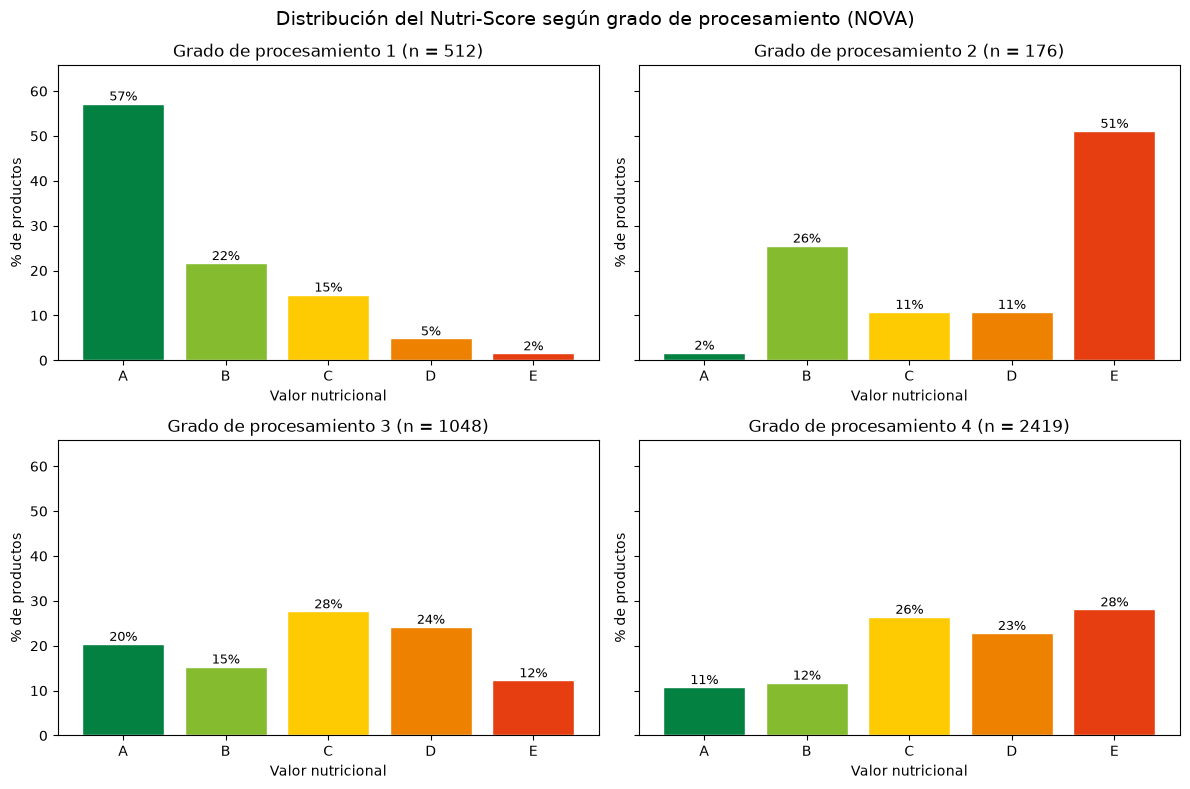

In [ ]:
# Hacemos un grafico de barras separado por grupos para ver cuantos productos hay en cada uno y que valor nutricional tienen.
# Podemos observar que si bien se ve una tendencia, el grado de procesamiento 2 rompe la regla.

datos_b = food_data_set[["grado_de_procesamiento", "grado_nutricional_numerico"]].dropna().astype(int)

tabla_b = pd.crosstab(datos_b["grado_de_procesamiento"], datos_b["grado_nutricional_numerico"], normalize="index") * 100
tabla_b = tabla_b.reindex(columns=range(1, 6), fill_value=0)
tabla_b.columns = ["A", "B", "C", "D", "E"]

cantidades_b = datos_b["grado_de_procesamiento"].value_counts().sort_index()

colores_nutri = ["#038141", "#85BB2F", "#FECB02", "#EE8100", "#E63E11"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)

for ax, nova in zip(axes.flatten(), [1, 2, 3, 4]):
    porcentajes = tabla_b.loc[nova]
    barras = ax.bar(porcentajes.index, porcentajes.values, color=colores_nutri, edgecolor="white")
    ax.bar_label(barras, fmt="%.0f%%", fontsize=9)
    ax.set_title(f"Grado de procesamiento {nova} (n = {cantidades_b[nova]})")
    ax.set_xlabel("Valor nutricional")
    ax.set_ylabel("% de productos")
    ax.set_ylim(0, tabla_b.values.max() * 1.15)

fig.suptitle("Distribución del Nutri-Score según grado de procesamiento (NOVA)", fontsize=14)
plt.tight_layout()
plt.show()

NOVA 1: 8.761046741604938e-28
NOVA 2: 6.589658884834675e-16
NOVA 3: 1.184729256730624e-25
NOVA 4: 1.5683496188817268e-39


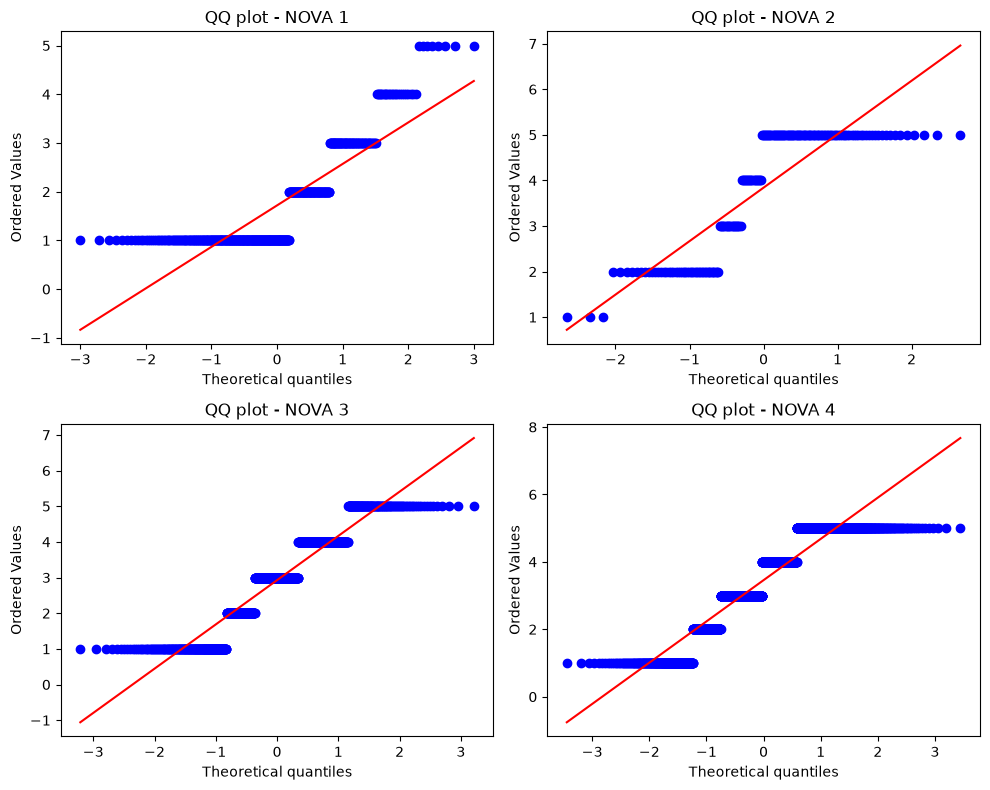

In [ ]:
# Chequeamos normalidad con shapiro
# Armamos los grupos por cada NOVA.

b1 = datos_b.loc[datos_b["grado_de_procesamiento"] == 1, "grado_nutricional_numerico"]
b2 = datos_b.loc[datos_b["grado_de_procesamiento"] == 2, "grado_nutricional_numerico"]
b3 = datos_b.loc[datos_b["grado_de_procesamiento"] == 3, "grado_nutricional_numerico"]
b4 = datos_b.loc[datos_b["grado_de_procesamiento"] == 4, "grado_nutricional_numerico"]

#Imprimimos los P valor para ver el resultado del test.
#H0 son normales, H1 no son normales.
print("NOVA 1:", stats.shapiro(b1).pvalue)
print("NOVA 2:", stats.shapiro(b2).pvalue)
print("NOVA 3:", stats.shapiro(b3).pvalue)
print("NOVA 4:", stats.shapiro(b4).pvalue)

# Hacemos los QQ Plot para ver la normalidad de manera grafica
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

stats.probplot(b1, dist="norm", plot=axes[0, 0])
axes[0, 0].set_title("QQ plot - NOVA 1")

stats.probplot(b2, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("QQ plot - NOVA 2")

stats.probplot(b3, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("QQ plot - NOVA 3")

stats.probplot(b4, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("QQ plot - NOVA 4")

plt.tight_layout()
plt.show()

#Observamos tanto de manera analitica como grafica que los grupos no siguen una distribucion normal.

In [ ]:
# Como no son normales, chequeamos Homosedastisidad con el test de levene.

resultado_levene_b = stats.levene(b1, b2, b3, b4)
print("p-valor Levene:", resultado_levene_b.pvalue)

p-valor Levene: 1.3213190265409173e-17


In [ ]:
# Como no se cumplen los supuestos hacemos un test No parametrico, Kruskal Wallis
# H0 El grado nutricional se distribuye igual en todos los grupos
# H1 Al menos un grupo difiere.

resultado_kw_b = stats.kruskal(b1, b2, b3, b4)
print("p-valor Kruskal-Wallis:", resultado_kw_b.pvalue)

for nombre, grupo in [("NOVA 1", b1), ("NOVA 2", b2), ("NOVA 3", b3), ("NOVA 4", b4)]:
    porcentaje_de = (grupo >= 4).mean() * 100
    print(f"{nombre}: mediana = {grupo.median()},  D {round(porcentaje_de, 1)} %")

p-valor Kruskal-Wallis: 1.2801817241019655e-150
NOVA 1: mediana = 1.0,  D 6.4 %
NOVA 2: mediana = 5.0,  D 61.9 %
NOVA 3: mediana = 3.0,  D 36.5 %
NOVA 4: mediana = 4.0,  D 51.0 %


In [ ]:
#Conclusion:
#El p valor observado es <0.05, lo que nos dice que no todos los grupos se distribuyen igual. Pero al analizar el grafico observamos que hay un patron
#entre los grupos 1,3 y 4.
# El grupo que rompe la regla es el NOVA 2. Al analizar que productos componen el grupo NOVA 2, vemos que son aceites, azucares, sal, manteca, vinagre...
# Estos alimentos, tienen bajo grado de procesamiento pero poco valor nutricional, ya que generalmente van acompañados de otros alimentos a la hora de consumirse.

grupo_2 = food_data_set[food_data_set["grado_de_procesamiento"] == 2]



print(f"Cantidad de productos en NOVA 2: {len(grupo_2)}")
print(grupo_2["nombre_producto"].head(15))



Cantidad de productos en NOVA 2: 206
47                          Sel de table iodé
61                 Spreadable Slightly Salted
84               Star vinaigre de table BLANC
129                             سكر الفانيلين
157                     Le Beurre Tendre Doux
248           Sirop d'érable ambré goût riche
264                               Runny Honey
373                Huile d'olive vierge extra
375                   vinaigre de table blanc
396    Maizena Fleur de Maïs Sans Gluten 400g
406                         Pure Irish Butter
509               Butter, lighter, spreadable
547                               Clear Honey
555                Chocolat noir Equateur Bio
558             Huile d'olive vierge de Maroc
Name: nombre_producto, dtype: str


# Hipotesis Multivariadas

## Energia explicada por macronutrientes (proteinas, grasas, carbohidratos)

In [ ]:
# Vamos a comprobar con un modelo de regresion lineal si la energia en kcal por 100g esta explicada por la cantidad de grasa, carbohidratos y proteinas por 100g.

# Encontramos una formula en internet que dice que las Kcalorias por 100g se calculan como: 9 * grasa + 4 * carbohidratos + 4 * proteinas. Vamos a ver si esto se cumple en nuestro dataset.


In [ ]:
# 1. Dataset solo con las variables del estudio
columnas = ["energia_kcal", "grasa_100g", "carbohidratos_cada_100g", "proteinas_cada_100g"]

df_energia = food_data_set[columnas].dropna().copy()

print("Filas originales:", len(food_data_set))
print("Filas sin nulos:", len(df_energia))


Filas originales: 4923
Filas sin nulos: 4619


In [ ]:
import statsmodels.formula.api as smf

# Sacamos las columnas auxiliares de los chequeos

# Modelo de regresión lineal múltiple
modelo = smf.ols(
    "energia_kcal ~ grasa_100g + carbohidratos_cada_100g + proteinas_cada_100g",
    data=df_energia
).fit()

print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:           energia_kcal   R-squared:                       0.974
Model:                            OLS   Adj. R-squared:                  0.974
Method:                 Least Squares   F-statistic:                 5.877e+04
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:29:51   Log-Likelihood:                -22726.
No. Observations:                4619   AIC:                         4.546e+04
Df Residuals:                    4615   BIC:                         4.549e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

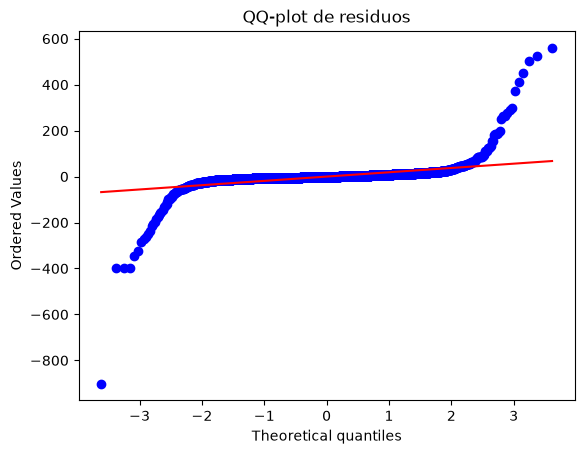

In [ ]:
residuos = modelo.resid

stats.probplot(residuos, dist="norm", plot=plt)
plt.title("QQ-plot de residuos")
plt.show()

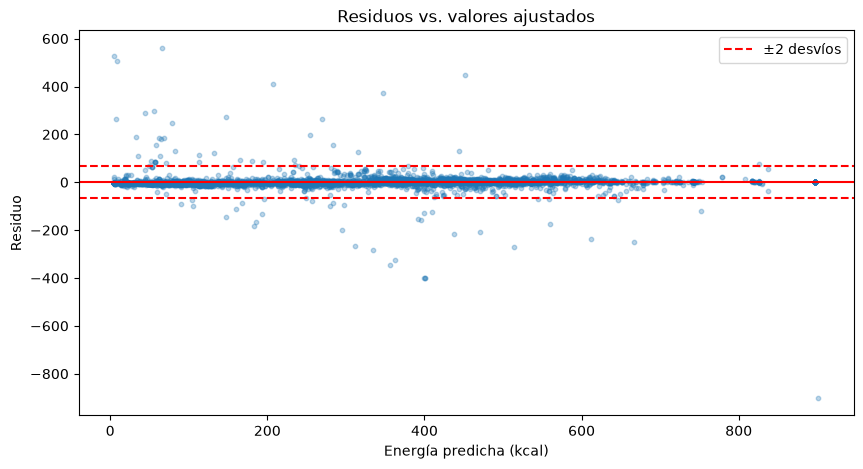

In [ ]:
predichos = modelo.fittedvalues
desvio = residuos.std()

plt.figure(figsize=(10, 5))
plt.scatter(predichos, residuos, alpha=0.3, s=10)

plt.axhline(0, color="red", linestyle="-")
plt.axhline(2 * desvio, color="red", linestyle="--", label="±2 desvíos")
plt.axhline(-2 * desvio, color="red", linestyle="--")

plt.xlabel("Energía predicha (kcal)")
plt.ylabel("Residuo")
plt.title("Residuos vs. valores ajustados")
plt.legend()
plt.show()

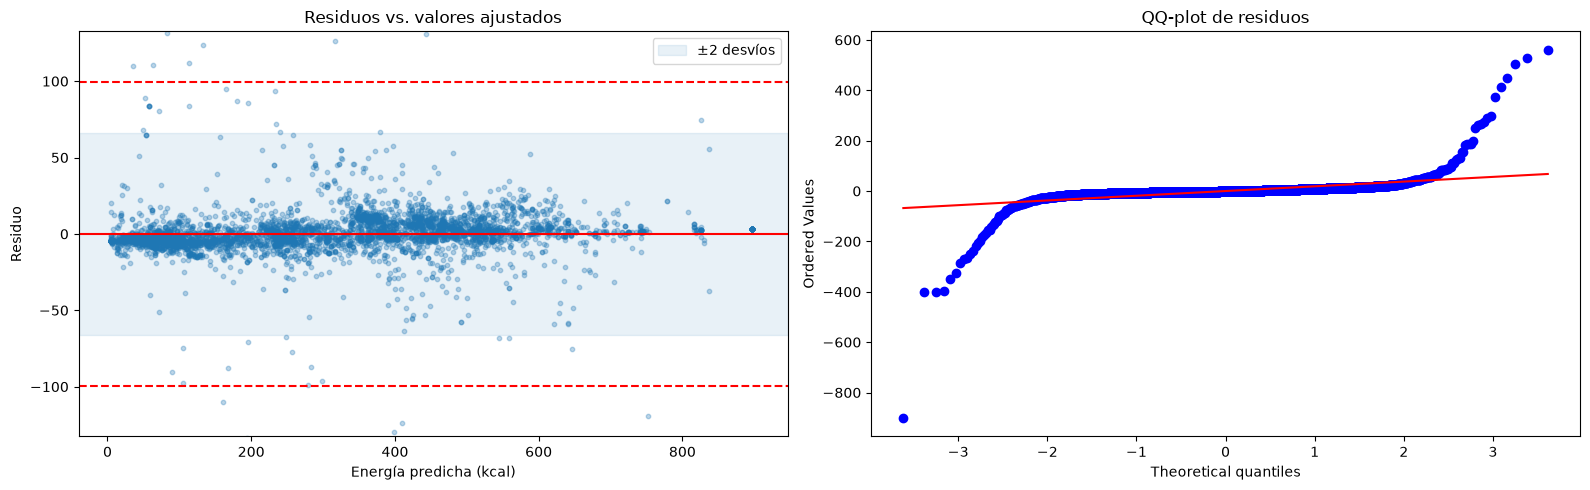

In [ ]:
residuos = modelo.resid
predichos = modelo.fittedvalues
desvio = residuos.std()

fig, ejes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Gráfico de bandas (homocedasticidad)
ejes[0].scatter(predichos, residuos, alpha=0.3, s=10)
ejes[0].axhspan(-2 * desvio, 2 * desvio, color="tab:blue", alpha=0.1, label="±2 desvíos")
ejes[0].axhline(0, color="red", linestyle="-")
ejes[0].axhline(3 * desvio, color="red", linestyle="--")
ejes[0].axhline(-3 * desvio, color="red", linestyle="--")
ejes[0].set_ylim(-4 * desvio, 4 * desvio)
ejes[0].set_xlabel("Energía predicha (kcal)")
ejes[0].set_ylabel("Residuo")
ejes[0].set_title("Residuos vs. valores ajustados")
ejes[0].legend()

# 2. QQ-plot (normalidad)
stats.probplot(residuos, dist="norm", plot=ejes[1])
ejes[1].set_title("QQ-plot de residuos")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

residuos = modelo.resid
predichos = modelo.fittedvalues
desvio = residuos.std()

# Tabla con real, predicho y residuo de cada producto
df_diag = df_energia.copy()
df_diag["predicho"] = predichos.round(1)
df_diag["residuo"] = residuos.round(1)

# 1. Valores extremos: residuo fuera de ±3 desvíos
extremos = df_diag[np.abs(df_diag["residuo"]) > 3 * desvio]
print(f"Valores extremos (fuera de ±3 desvíos): {len(extremos)} de {len(df_diag)}")
print(f"Porcentaje: {len(extremos) / len(df_diag) * 100:.2f} %")
display(extremos.sort_values("residuo").head(15))

# 2. Caso particular: energía 0 pero con macronutrientes cargados
suma_macros = (
    df_diag["grasa_100g"]
    + df_diag["carbohidratos_cada_100g"]
    + df_diag["proteinas_cada_100g"]
)
energia_cero = df_diag[(df_diag["energia_kcal"] == 0) & (suma_macros > 0)]
print(f"\nProductos con energía 0 y macros cargados: {len(energia_cero)}")
display(energia_cero.sort_values("predicho", ascending=False))

Valores extremos (fuera de ±3 desvíos): 51 de 4619
Porcentaje: 1.10 %


,energia_kcal,grasa_100g,carbohidratos_cada_100g,proteinas_cada_100g,predicho,residuo
856,0.000000,100.000000,0.000000,1.000000,901.4,-901.4
437,2.000000,0.200000,99.000000,0.000000,401.1,-399.1
2890,2.000000,0.200000,99.000000,0.000000,401.1,-399.1
1949,1.000000,0.000000,99.000000,0.000000,399.4,-398.4
3305,9.000000,1.200000,83.000000,2.300000,356.4,-347.4
4170,38.000000,0.020000,89.000000,0.500000,361.9,-323.9
547,50.000000,0.000000,82.400000,0.300000,334.5,-284.5
1212,243.000000,28.700000,53.500000,9.130000,514.4,-271.4
3939,46.950000,0.000000,76.900000,0.020000,311.3,-264.4
1697,416.000000,65.200000,16.000000,3.800000,667.0,-251.0



Productos con energía 0 y macros cargados: 7


,energia_kcal,grasa_100g,carbohidratos_cada_100g,proteinas_cada_100g,predicho,residuo
856,0.0,100.00,0.0,1.00,901.4,-901.4
4846,0.0,20.00,0.0,0.00,183.1,-183.1
4350,0.0,4.00,9.1,3.10,90.3,-90.3
0,0.0,0.00,4.2,0.00,21.4,-21.4
2483,0.0,0.00,1.0,0.00,8.6,-8.6
3993,0.0,0.10,0.1,0.10,6.4,-6.4
1240,0.0,0.02,0.0,0.12,5.4,-5.4


## El grado de procesamiento industrial (NOVA), la categoría del producto y la cantidad de alérgenos declarados explican conjuntamente la probabilidad de que un producto reciba una calificación Nutri-Score desfavorable (D/E), sin utilizar directamente su composición nutricional.

In [ ]:


# Columnas del estudio
col_nutri = "grado_nutricional_numerico"  # grado 1 a 5 (A a E)
col_nova = "grado_de_procesamiento"       # grado 1 a 4
col_categoria = "categoria_principal"
col_alergenos = "cantidad_alergenos"

df_logistica = food_data_set[[col_nutri, col_nova, col_categoria, col_alergenos]].dropna().copy()

# Variable objetivo: 1 = Desfavorable (D/E), 0 = Favorable (A/B/C)
df_logistica["desfavorable"] = (df_logistica[col_nutri] >= 4).astype(int)

print("Cantidad de productos:", len(df_logistica))
print(df_logistica["desfavorable"].value_counts(normalize=True).round(3))

Cantidad de productos: 4155
desfavorable
0    0.577
1    0.423
Name: proportion, dtype: float64


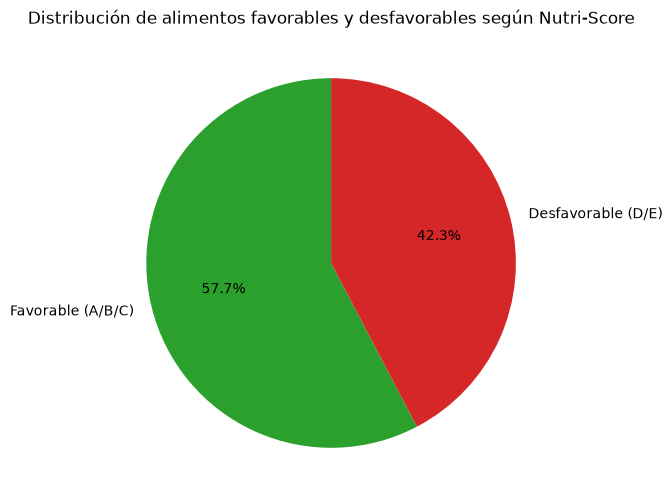

In [ ]:
conteo = df_logistica["desfavorable"].value_counts().sort_index()

plt.figure(figsize=(6, 6))
plt.pie(
    conteo.values,
    labels=["Favorable (A/B/C)", "Desfavorable (D/E)"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["tab:green", "tab:red"]
)
plt.title("Distribución de alimentos favorables y desfavorables según Nutri-Score")
plt.show()

In [ ]:
# Vamos a pasar todas las variables cualitativas ordinales que tenemos a variables dummies para poder hacer un modelo de regresion logistica.

# Variables predictoras
X = df_logistica[["grado_de_procesamiento", "categoria_principal", "cantidad_alergenos"]]

# NOVA y categoría pasan a dummies; alérgenos queda numérica
X = pd.get_dummies(
    X,
    columns=["grado_de_procesamiento", "categoria_principal"],
    drop_first=True,
    dtype=int
)

# Variable objetivo
y = df_logistica["desfavorable"]

print("Cantidad de variables del modelo:", X.shape[1])
print(X.columns.tolist())
X.head()

Cantidad de variables del modelo: 10
['cantidad_alergenos', 'grado_de_procesamiento_2', 'grado_de_procesamiento_3', 'grado_de_procesamiento_4', 'categoria_principal_breakfasts', 'categoria_principal_condiments', 'categoria_principal_dairies', 'categoria_principal_otros', 'categoria_principal_plant-based-foods-and-beverages', 'categoria_principal_snacks']


,cantidad_alergenos,grado_de_procesamiento_2,grado_de_procesamiento_3,grado_de_procesamiento_4,categoria_principal_breakfasts,categoria_principal_condiments,categoria_principal_dairies,categoria_principal_otros,categoria_principal_plant-based-foods-and-beverages,categoria_principal_snacks
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
5,1,0,1,0,0,0,1,0,0,0
6,0,0,0,0,0,0,0,0,0,0
7,1,0,1,0,0,0,1,0,0,0


In [ ]:
from sklearn.model_selection import train_test_split

# 80% entrenamiento, 20% test, manteniendo la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=10
)

print("Entrenamiento:", X_train.shape)
print("Test:", X_test.shape)

# Verificamos que el estratificado haya funcionado
print("\nProporción de desfavorables en entrenamiento:", round(y_train.mean(), 3))
print("Proporción de desfavorables en test:", round(y_test.mean(), 3))

Entrenamiento: (3324, 10)
Test: (831, 10)

Proporción de desfavorables en entrenamiento: 0.423
Proporción de desfavorables en test: 0.424


In [ ]:
# Estandarizamos las variables para que tengan media 0 desvio 1.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Se ajusta SOLO con entrenamiento
scaler.fit(X_train)

# Se aplica a ambos conjuntos con las medias y desvíos de entrenamiento
X_train_stand = scaler.transform(X_train)
X_test_stand = scaler.transform(X_test)

print("Media de las variables en entrenamiento (debería ser ~0):", X_train_stand.mean(axis=0).round(2)[:5])
print("Desvío de las variables en entrenamiento (debería ser ~1):", X_train_stand.std(axis=0).round(2)[:5])

Media de las variables en entrenamiento (debería ser ~0): [-0.  0. -0.  0.  0.]
Desvío de las variables en entrenamiento (debería ser ~1): [1. 1. 1. 1. 1.]


In [ ]:
# Entrenamos el modelo.

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# Modelo de regresión logística sin regularización
baseline_logistic_model = LogisticRegression(C=np.inf, max_iter=1000, random_state=10)

# Validación cruzada con 5 particiones sobre entrenamiento
cv_scores = cross_val_score(
    baseline_logistic_model,
    X_train_stand,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Exactitud en cada fold:", cv_scores.round(3))
print("Exactitud promedio:", round(cv_scores.mean(), 3))
print("Desvío de la exactitud:", round(cv_scores.std(), 3))

# Entrenamos el modelo final con todo el conjunto de entrenamiento
baseline_logistic_model.fit(X_train_stand, y_train)

Exactitud en cada fold: [0.726 0.735 0.732 0.75  0.748]
Exactitud promedio: 0.739
Desvío de la exactitud: 0.009


,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",inf
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",10
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [ ]:
# Ajustamos el modelo con el regularizador.

from sklearn.model_selection import GridSearchCV

# Valores de C a probar
param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}

# Regresión logística con regularización L2 (por defecto)
logistic_model = LogisticRegression(max_iter=1000, random_state=10)

# Búsqueda con validación cruzada de 5 particiones
grid_search = GridSearchCV(logistic_model, param_grid, cv=5, scoring="accuracy")
grid_search.fit(X_train_stand, y_train)

print("Mejor C:", grid_search.best_params_["C"])
print("Mejor exactitud:", round(grid_search.best_score_, 3))
print("Exactitud sin regularizar:", round(cv_scores.mean(), 3))

# Guardamos el mejor modelo
best_logistic_model = grid_search.best_estimator_

Mejor C: 0.1
Mejor exactitud: 0.745
Exactitud sin regularizar: 0.739


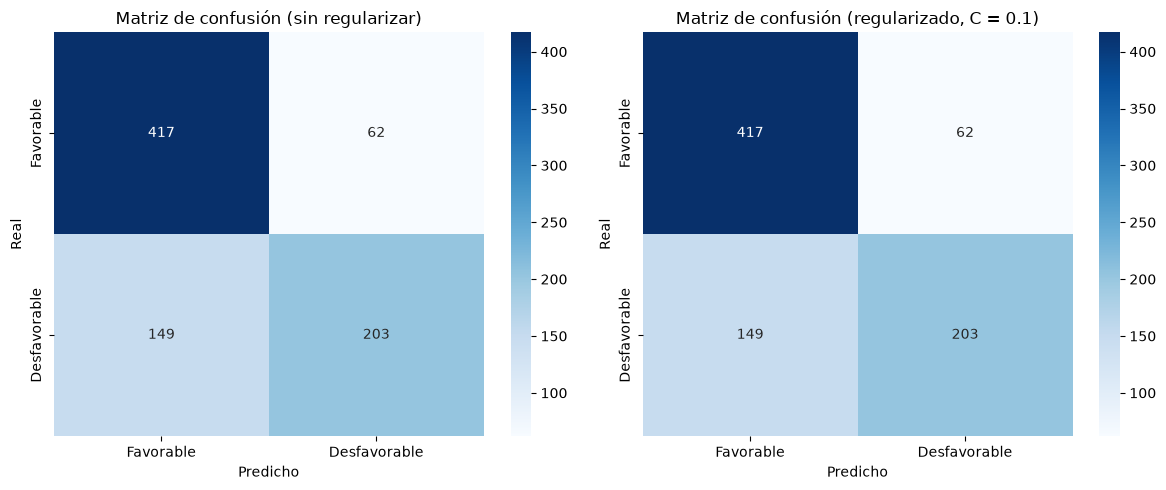

Exactitud prediciendo siempre la clase mayoritaria: 0.576
Exactitud del modelo sin regularizar: 0.746
Exactitud del modelo regularizado: 0.746


In [ ]:
#Test

import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix

# Predicciones de los dos modelos sobre test
y_pred_original = baseline_logistic_model.predict(X_test_stand)
y_pred_best = best_logistic_model.predict(X_test_stand)

# Matrices de confusión, una al lado de la otra
clases = ["Favorable", "Desfavorable"]
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_original), annot=True, fmt="d", cmap="Blues",
            xticklabels=clases, yticklabels=clases, ax=ejes[0])
ejes[0].set_title("Matriz de confusión (sin regularizar)")
ejes[0].set_xlabel("Predicho")
ejes[0].set_ylabel("Real")

sns.heatmap(confusion_matrix(y_test, y_pred_best), annot=True, fmt="d", cmap="Blues",
            xticklabels=clases, yticklabels=clases, ax=ejes[1])
ejes[1].set_title("Matriz de confusión (regularizado, C = 0.1)")
ejes[1].set_xlabel("Predicho")
ejes[1].set_ylabel("Real")

plt.tight_layout()
plt.show()

# Exactitudes
accuracy_mayoritaria = y_test.value_counts(normalize=True).max()

print("Exactitud prediciendo siempre la clase mayoritaria:", round(accuracy_mayoritaria, 3))
print("Exactitud del modelo sin regularizar:", round(accuracy_score(y_test, y_pred_original), 3))
print("Exactitud del modelo regularizado:", round(accuracy_score(y_test, y_pred_best), 3))

C:\Users\s7\AppData\Local\Temp\ipykernel_23444\1689279600.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(coeficientes.index, rotation=90)


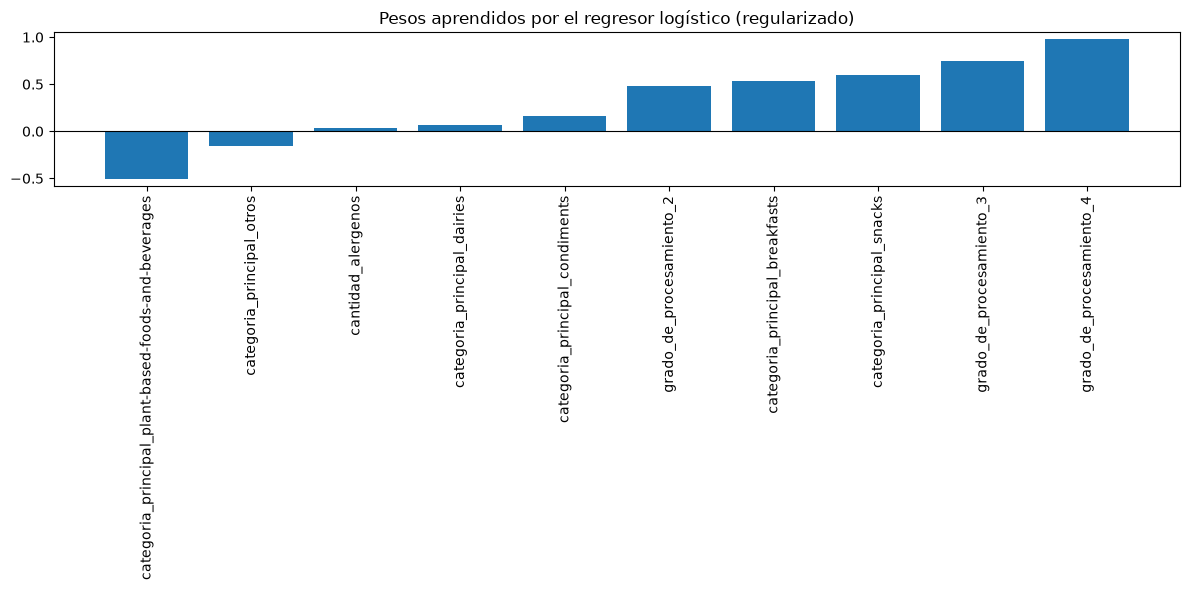

In [ ]:
coeficientes = pd.Series(best_logistic_model.coef_[0], index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(coeficientes.index, coeficientes.values)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticklabels(coeficientes.index, rotation=90)
ax.set_title("Pesos aprendidos por el regresor logístico (regularizado)")
plt.tight_layout()
plt.show()